In [1]:
import os
import numpy as np
import pandas as pd
from collections import defaultdict
from tqdm import trange, tqdm

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances
import pickle

from utils import *

In [2]:
df_slopp = pd.read_csv('processed_data/df_slopp.csv')
df_slopp_e = pd.read_csv('processed_data/df_slopp_e.csv')

df_slopp = df_slopp.merge(df_slopp.
 groupby('file_name').
 count().
 query('wavelength>1000').
 reset_index().
 iloc[:,:2], on='file_name', how='inner')

del df_slopp['Unnamed: 0_x']
del df_slopp['Unnamed: 0_y']


df_slopp_e = df_slopp_e.merge(df_slopp_e.
 groupby('file_name').
 count().
 query('wavelength>1000').
 reset_index().
 iloc[:,:2], on='file_name', how='inner')

del df_slopp_e['Unnamed: 0_x']
del df_slopp_e['Unnamed: 0_y']

df_slopp_slopp_e = pd.concat([df_slopp, df_slopp_e])

df_slopp_slopp_e_int = interpol_spect(df_slopp_slopp_e, min_wl=0, max_wl=4000, n=1846)

slopp_slopp_e_pivot = df_slopp_slopp_e_int.pivot(
    index=['file_name', 'polymer'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [6]:
np.diff(slopp_slopp_e_pivot.iloc[0:1,2:].columns)
np.unique(slopp_slopp_e_pivot['polymer'])

array(['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cellulose Acetate',
       'Cotton', 'Dyed Cellulose', 'Polyamide',
       'Polybutylene Terephthalate', 'Polycarbonate', 'Polyester',
       'Polyethylene', 'Polyethylene Terephthalate',
       'Polyethylene Vinyl Acetate', 'Polyethylene-co-Polypropylene',
       'Polymethyl Methacrylate', 'Polypropylene', 'Polystyrene',
       'Polystyrene-co-Polyvinyl Chloride', 'Polyurethane',
       'Polyvinyl Chloride', 'Rubber'], dtype=object)

Polyethylene 10. Grey Grocery Bag.txt
Polyethylene 10. Grey Grocery Bag.txt 1346


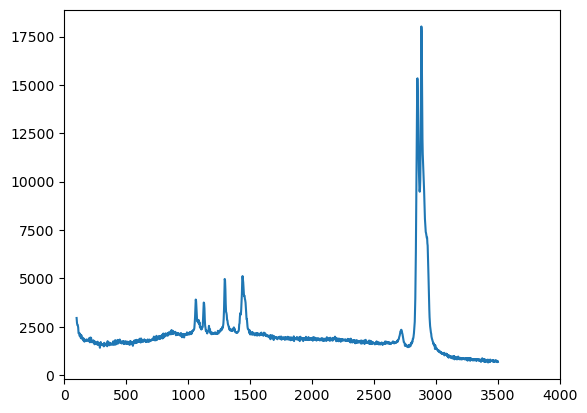

Polyethylene 11. Green Toy.txt
Polyethylene 11. Green Toy.txt 1346


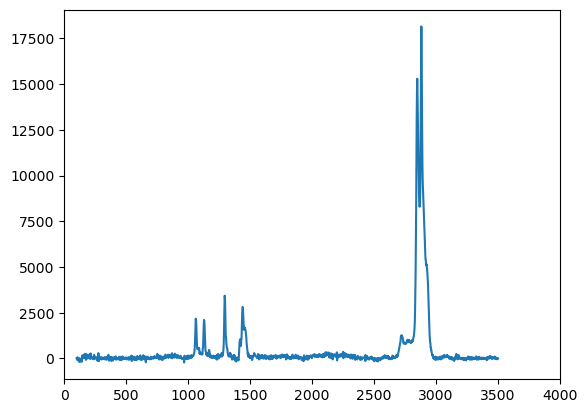

Polyethylene 12. Black Pen Lid.txt
Polyethylene 12. Black Pen Lid.txt 1346


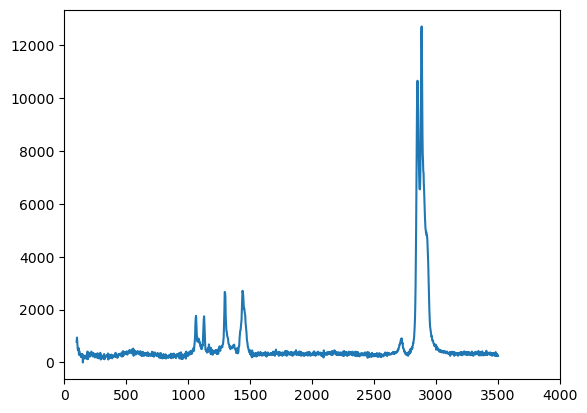

Polyethylene 14. Green Wrapper.txt
Polyethylene 14. Green Wrapper.txt 1346


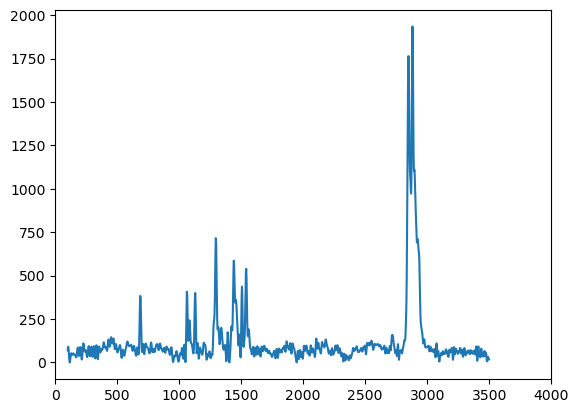

Polyethylene 15. Green Tampon Applicator.txt
Polyethylene 15. Green Tampon Applicator.txt 1346


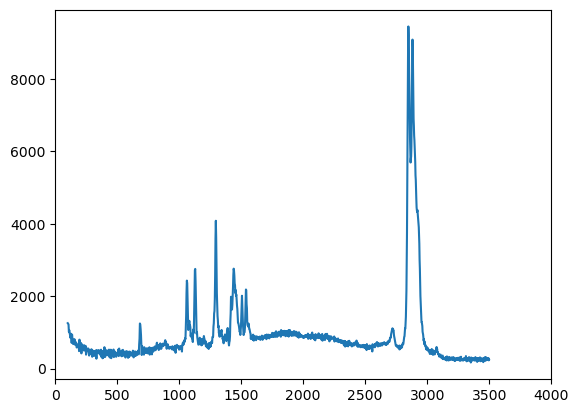

Polyethylene 16. White Art Foam.txt
Polyethylene 16. White Art Foam.txt 1346


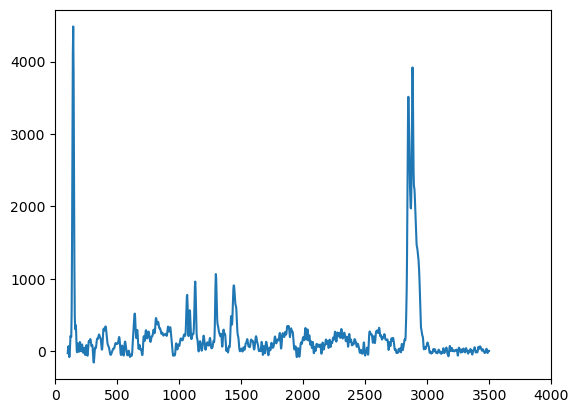

Polyethylene 19. Grey Cosmetics Bottle.txt
Polyethylene 19. Grey Cosmetics Bottle.txt 1346


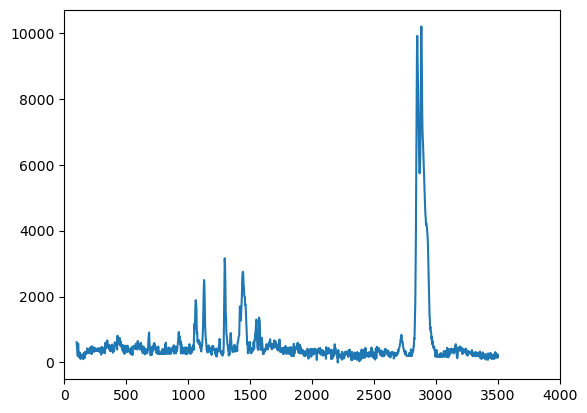

Polyethylene 2. Brown Food Container.txt
Polyethylene 2. Brown Food Container.txt 1346


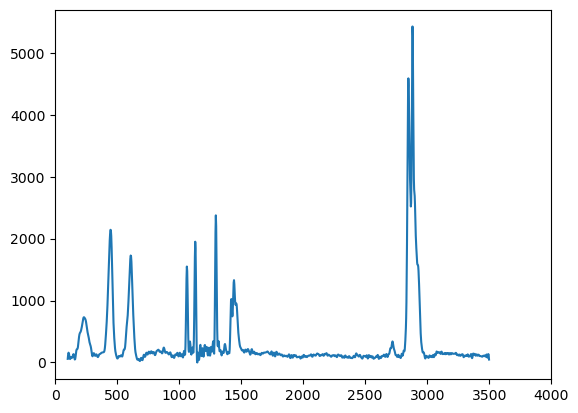

Polyethylene 20. White Microsphere.txt
Polyethylene 20. White Microsphere.txt 1346


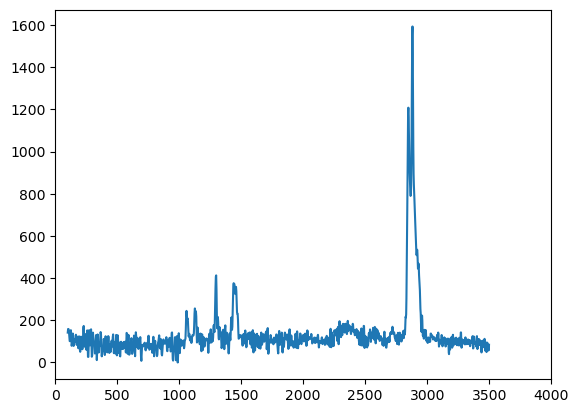

Polyethylene 21. Yellow Container Lid.txt
Polyethylene 21. Yellow Container Lid.txt 1346


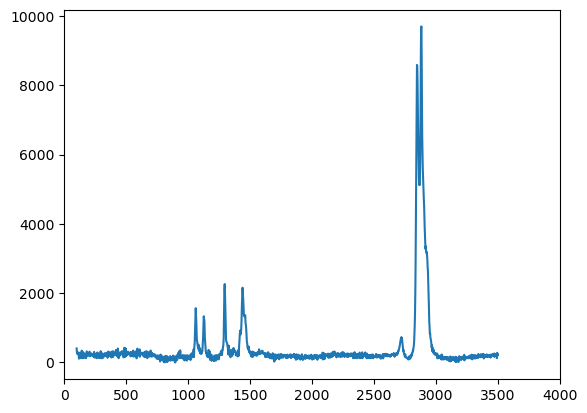

Polyethylene 22. Blue Container Lid.txt
Polyethylene 22. Blue Container Lid.txt 1346


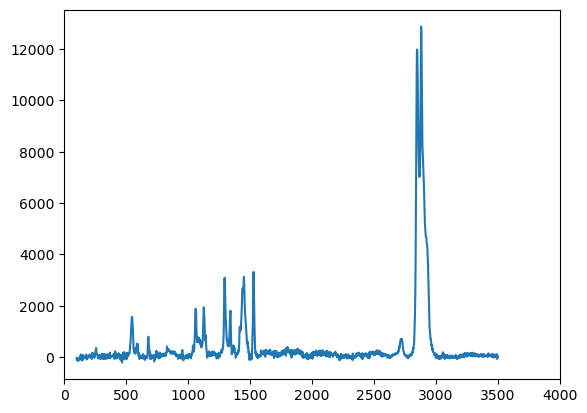

Polyethylene 23. Clear Cereal Bag.txt
Polyethylene 23. Clear Cereal Bag.txt 1346


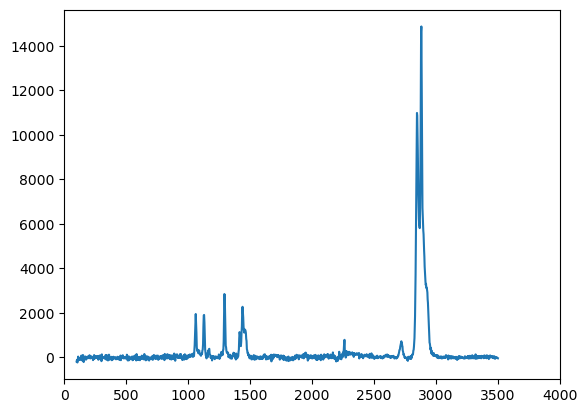

Polyethylene 28. Blue Microbead.txt
Polyethylene 28. Blue Microbead.txt 1346


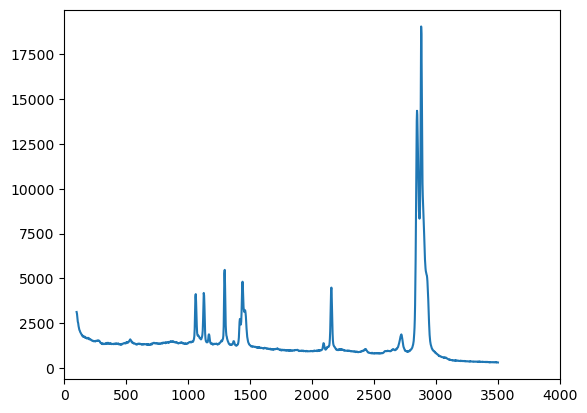

Polyethylene 3. Turquoise Bin.txt
Polyethylene 3. Turquoise Bin.txt 1346


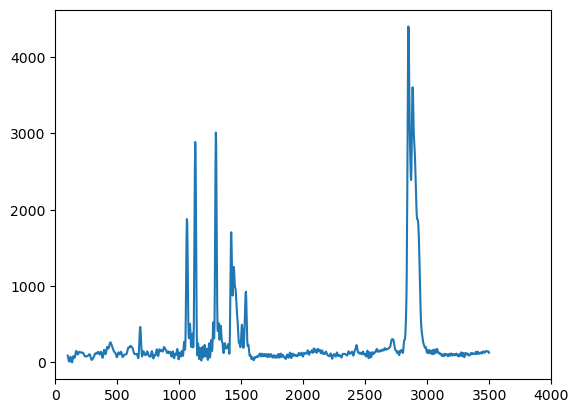

Polyethylene 4. Orange Bin.txt
Polyethylene 4. Orange Bin.txt 1346


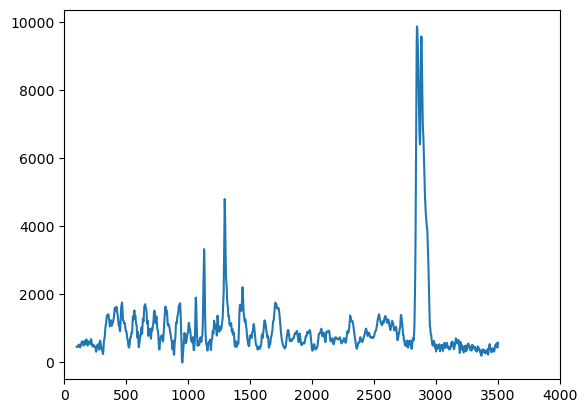

Polyethylene 5. Green Microsphere.txt
Polyethylene 5. Green Microsphere.txt 1346


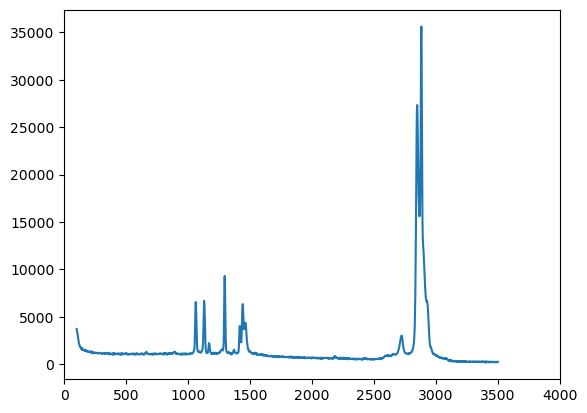

Polyethylene 6. White Microsphere.txt
Polyethylene 6. White Microsphere.txt 1346


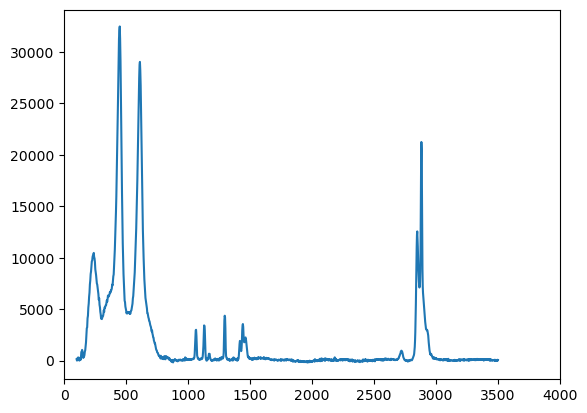

Polyethylene 7. Clear Cling Wrap.txt
Polyethylene 7. Clear Cling Wrap.txt 1346


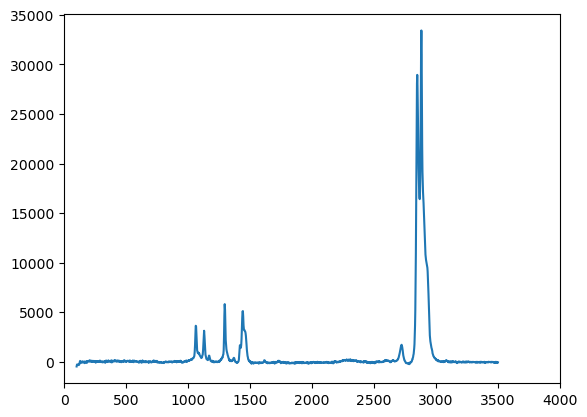

Polyethylene 9. White Grocery Bag.txt
Polyethylene 9. White Grocery Bag.txt 1346


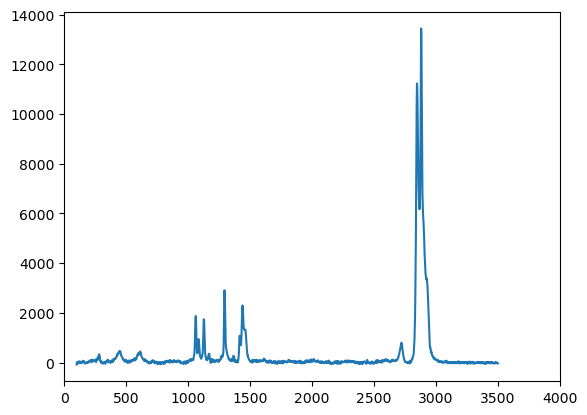

In [4]:
#df_slopp = pd.read_csv('processed_data/df_slopp.csv')
id_pp = np.unique(df_slopp.query('polymer == "Polyethylene"')['file_name'])

for name in id_pp:
    print(name)
    wn_ = df_slopp.query('file_name == @name')['wavelength']
    int_ = df_slopp.query('file_name == @name')['intensity']
    print(name, wn_.shape[0])
    plt.plot(wn_, int_)
    plt.xlim(0,4000)
    plt.show()

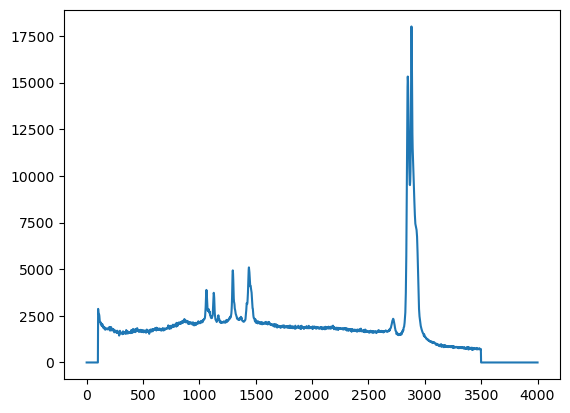

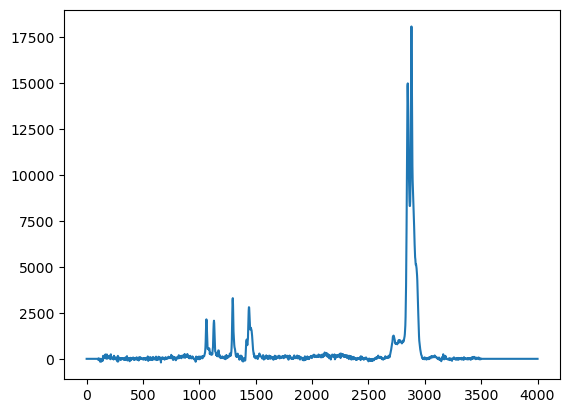

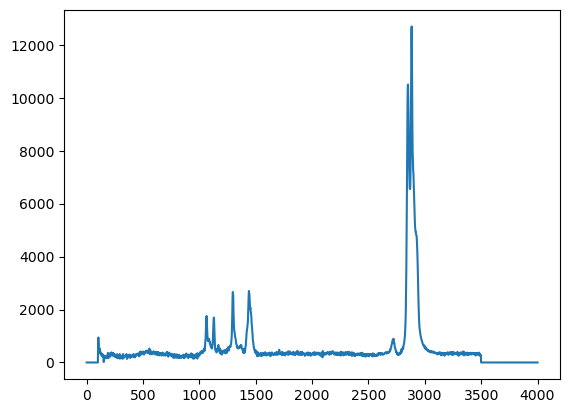

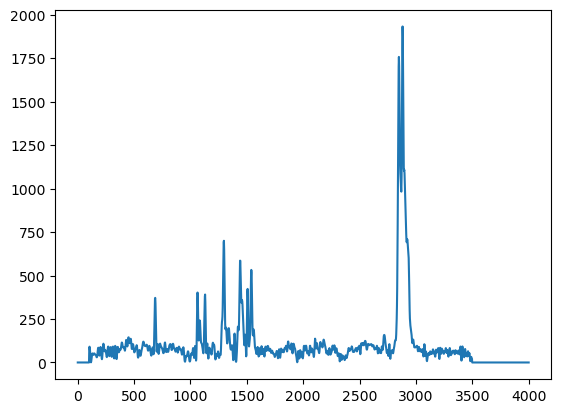

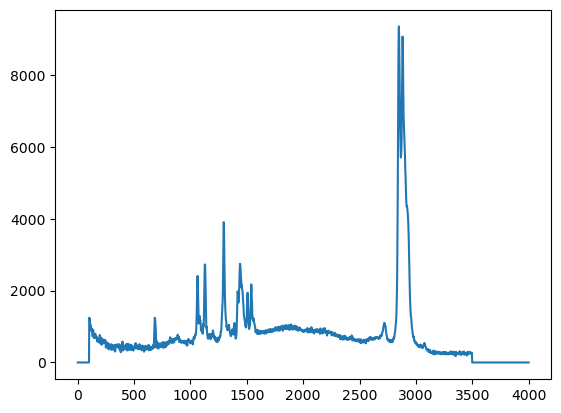

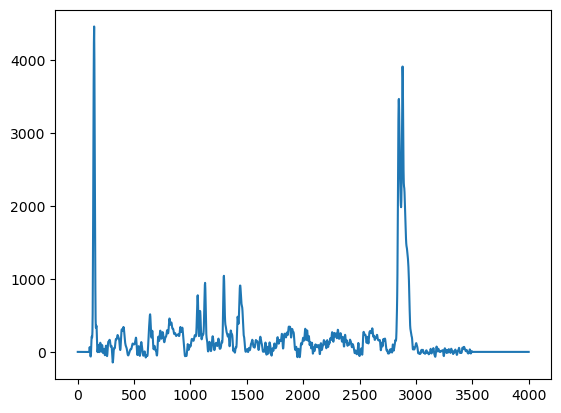

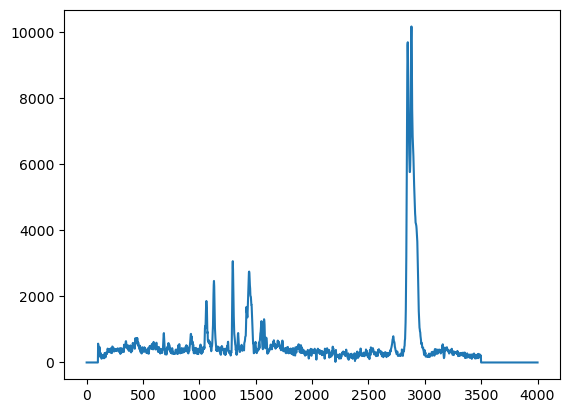

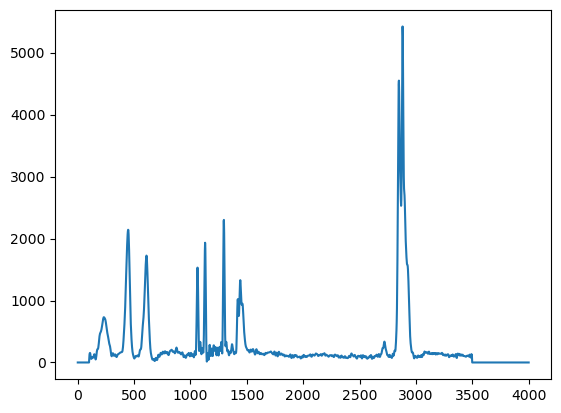

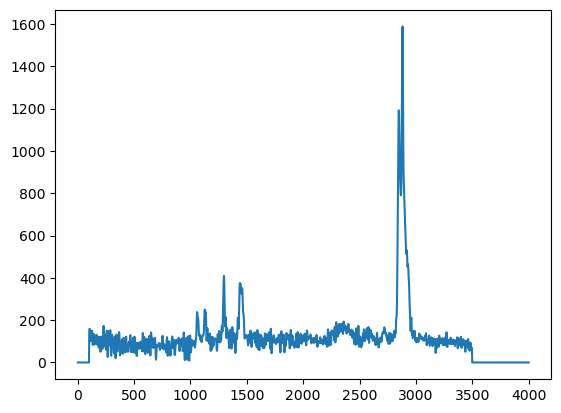

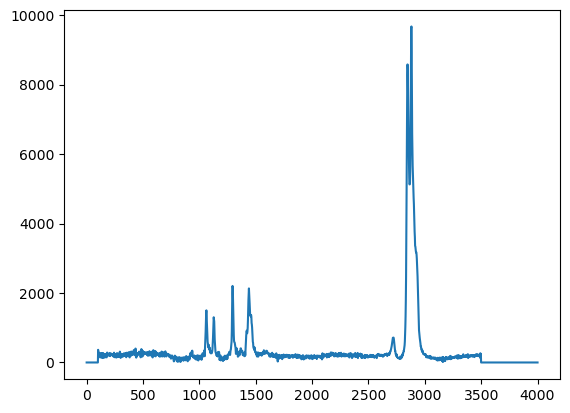

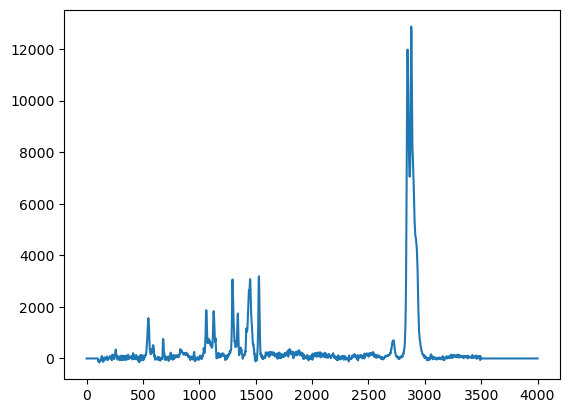

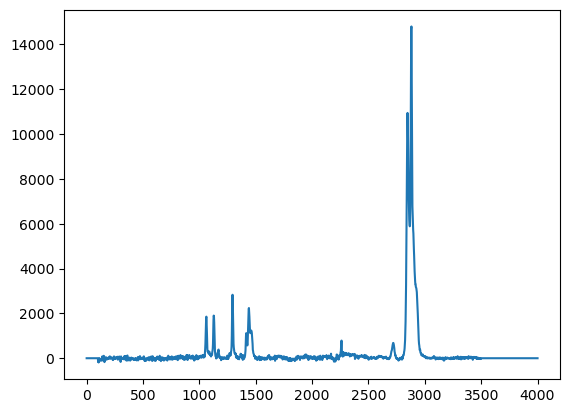

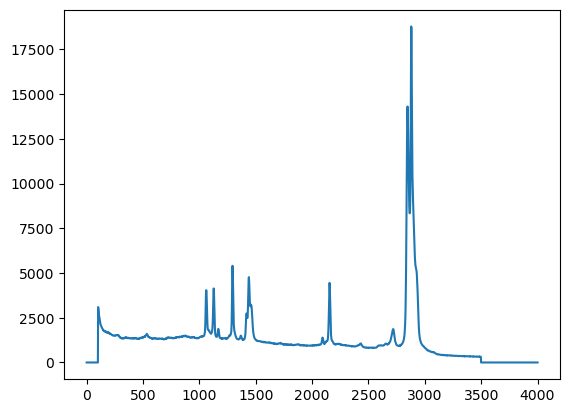

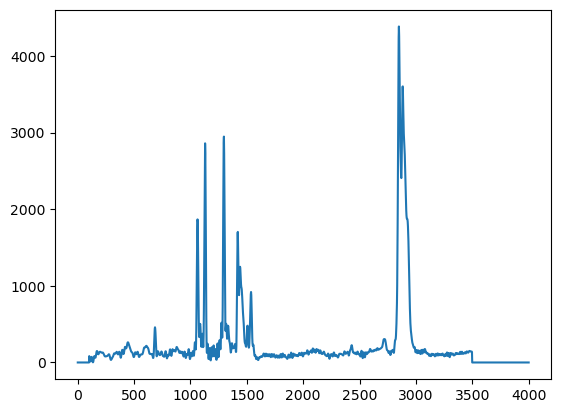

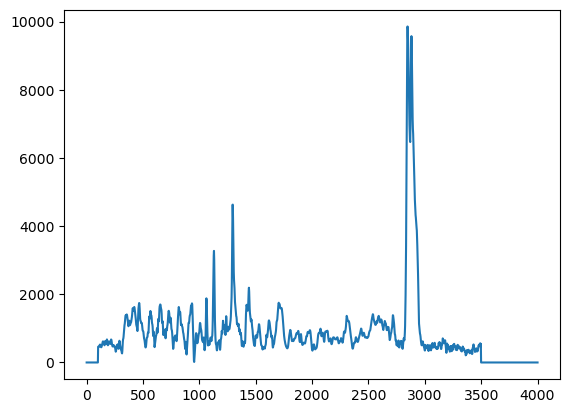

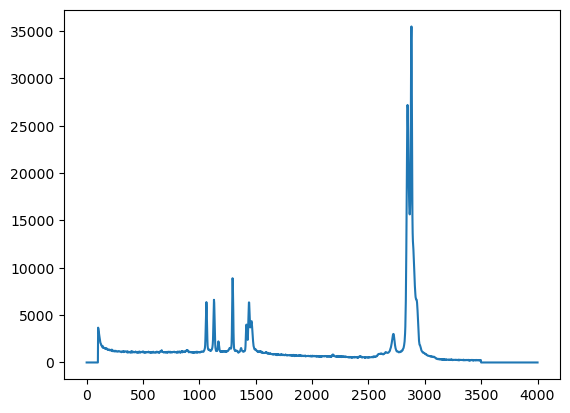

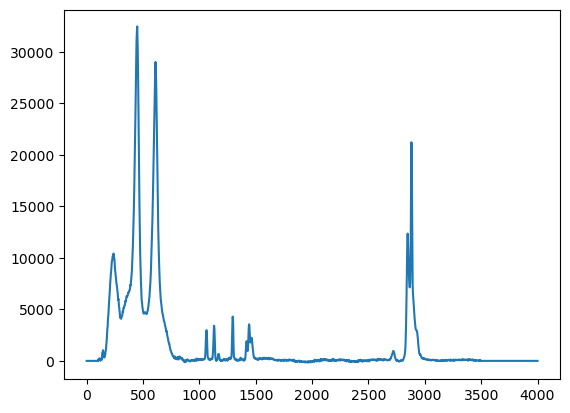

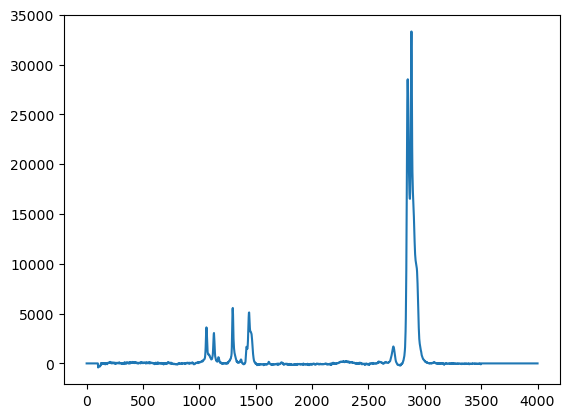

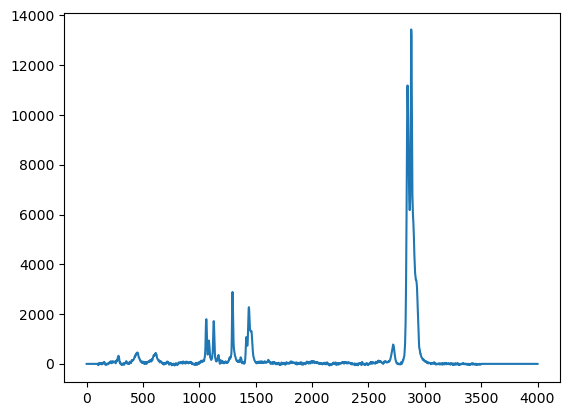

In [6]:
for name in id_pp:
    wn_ = df_slopp_slopp_e_int.query('file_name == @name')['wavelength']
    int_ = df_slopp_slopp_e_int.query('file_name == @name')['intensity']
    plt.plot(wn_, int_)
    plt.show()

In [7]:
flopp_flopp_e_pivot = pd.read_csv('processed_data/flopp_flopp_e_pivot.csv')
#slopp_slopp_e_pivot = pd.read_csv('processed_data/slopp_slopp_e_pivot.csv')

In [15]:
np.diff(np.float64(flopp_flopp_e_pivot.iloc[0:1,4:].columns))

array([1.9285, 1.9286, 1.9286, ..., 1.928 , 1.929 , 1.929 ])

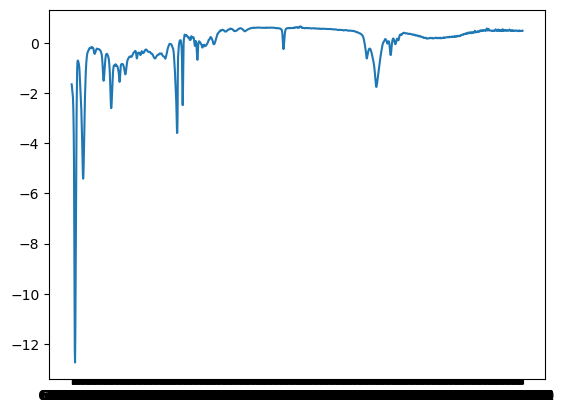

In [104]:
_ = plt.plot(flopp_flopp_e_pivot.iloc[0,4:].T)

In [105]:
flopp_flopp_e_pivot.iloc[0,4:]

674.9918   -1.652339
676.9203   -1.716827
678.8489   -1.864428
680.7775   -1.967062
682.706    -2.049846
              ...   
3992.094    0.479669
3994.023    0.483015
3995.951    0.476869
3997.88     0.475167
3999.809    0.482083
Name: 0, Length: 1725, dtype: object

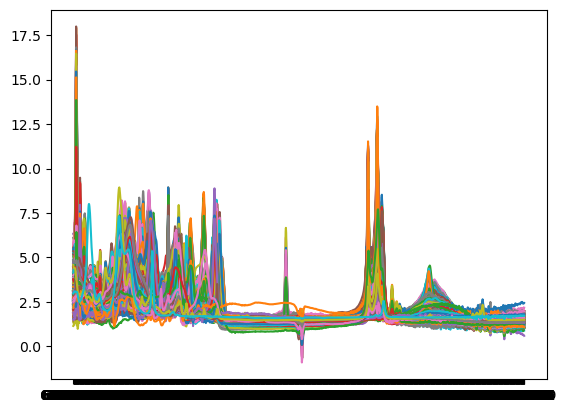

In [106]:
_=plt.plot(2-flopp_flopp_e_pivot.iloc[:,4:].T)

In [107]:
spectra_data = pd.read_csv('gloves_contamination/data_ir.csv')
del spectra_data['Unnamed: 0']
#spectra_data
#idx_nans_ir = np.unique(np.where(np.isnan(spectra_data.iloc[:,:-6]))[0])
#id_nans_ir = spectra_data.iloc[idx_nans_ir,-6]
id_nans_ir = list(spectra_data.loc[np.array(pd.DataFrame({'id':np.where(np.isnan(spectra_data.iloc[:,:-7]))[0],'n':1}).groupby('id').sum() > 418),'id'])
#spectra_data.query('id in @id_nans_ir')

In [112]:
spectra_data_raman = pd.read_csv('gloves_contamination/data_raman.csv')
del spectra_data_raman['Unnamed: 0']
#idx_nans_raman = np.unique(np.where(np.isnan(spectra_data_raman.iloc[:,:-6]))[0])
#id_nans_raman = spectra_data_raman.iloc[idx_nans,-6]
#spectra_data_raman.query('id not in @id_nans_raman')
#spectra_data_raman.loc[np.array(pd.DataFrame({'id':np.where(np.isnan(spectra_data_raman.iloc[:,:-6]))[0],'n':1}).groupby('id').sum() > 418),'id']
id_nans_raman = list(spectra_data_raman.iloc[np.array(pd.DataFrame({'id':np.where(np.isnan(spectra_data_raman.iloc[:,:-7]))[0],'n':1}).groupby('id').sum().index),-7])


In [113]:
id_nans = np.unique(id_nans_ir + id_nans_raman)

spectra_data = spectra_data.query('id not in @id_nans').reset_index(drop=True)
spectra_data_raman = spectra_data_raman.query('id not in @id_nans').reset_index(drop=True)


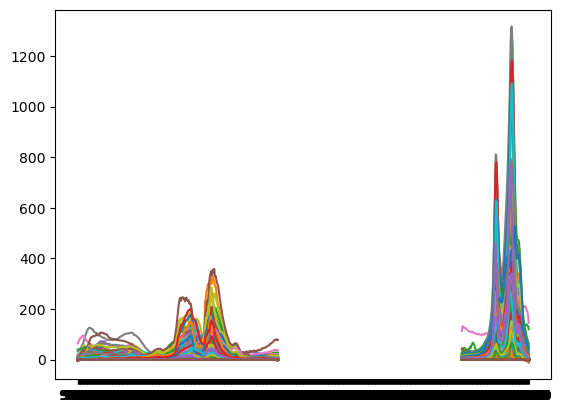

In [114]:
_ = plt.plot(spectra_data.iloc[:,:-7].T)

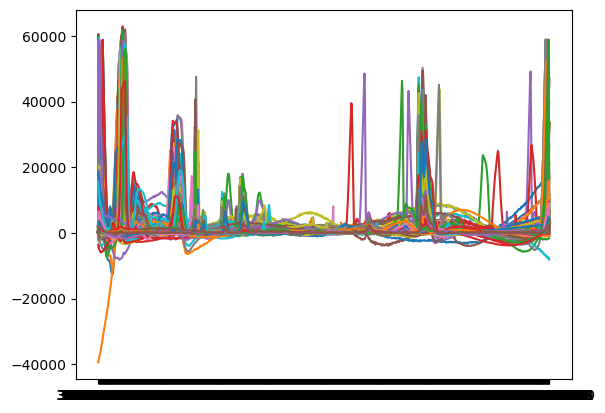

In [115]:
_ = plt.plot(spectra_data_raman.iloc[:,:-7].T)

In [116]:
spectra_data_long = spectra_data.iloc[:, :-6].melt(id_vars='id')#
spectra_data_long.iloc[:,1:] = spectra_data_long.iloc[:,1:].astype('float32')

spectra_data_long.columns = ['file_name','wavelength','intensity']
spectra_data_long['polymer'] = ''
spectra_data_long_int = interpol_spect(spectra_data_long, min_wl=674.9918, max_wl=3999.809,n=1725)
spectra_data_int = spectra_data_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [117]:
spectra_data_int

wavelength,file_name,674.9918,676.9203482598608,678.8488965197216,680.7774447795824,682.7059930394431,684.6345412993039,686.5630895591647,688.4916378190255,690.4201860788863,...,3982.452065661253,3984.3806139211138,3986.3091621809745,3988.237710440835,3990.1662587006967,3992.0948069605574,3994.023355220418,3995.951903480279,3997.8804517401395,3999.809
0,Blank_-_01_0521_1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Blank_-_01_0521_10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Blank_-_01_0521_11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Blank_-_01_0521_12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Blank_-_01_0521_13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,MF_N_02_0409_95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1482,MF_N_02_0409_96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1483,MF_N_02_0409_97,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1484,MF_N_02_0409_98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


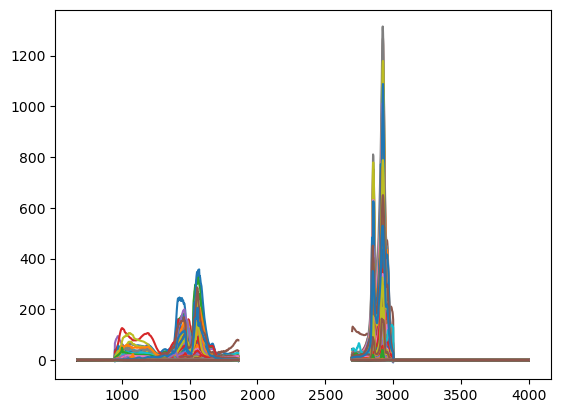

In [118]:
_=plt.plot(spectra_data_int.iloc[:,1:].T)

In [119]:
spectra_data_raman_long = spectra_data_raman.iloc[:, :-6].melt(id_vars='id')#
spectra_data_raman_long.iloc[:,1:] = spectra_data_raman_long.iloc[:,1:].astype('float32')

spectra_data_raman_long.columns = ['file_name','wavelength','intensity']
spectra_data_raman_long['polymer'] = ''
spectra_data_raman_long_int = interpol_spect(spectra_data_raman_long, min_wl=0, max_wl=3999.57,n=1846)
spectra_data_raman_int = spectra_data_raman_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

In [120]:
spectra_data_raman_int

wavelength,file_name,0.0,2.167788617886179,4.335577235772358,6.503365853658536,8.671154471544716,10.838943089430895,13.006731707317073,15.174520325203252,17.34230894308943,...,3980.0599024390244,3982.2276910569108,3984.3954796747967,3986.563268292683,3988.7310569105694,3990.8988455284552,3993.0666341463416,3995.234422764228,3997.402211382114,3999.57
0,Blank_-_01_0521_1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Blank_-_01_0521_10,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,Blank_-_01_0521_11,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,Blank_-_01_0521_12,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,Blank_-_01_0521_13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1481,MF_N_02_0409_95,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1482,MF_N_02_0409_96,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1483,MF_N_02_0409_97,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1484,MF_N_02_0409_98,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


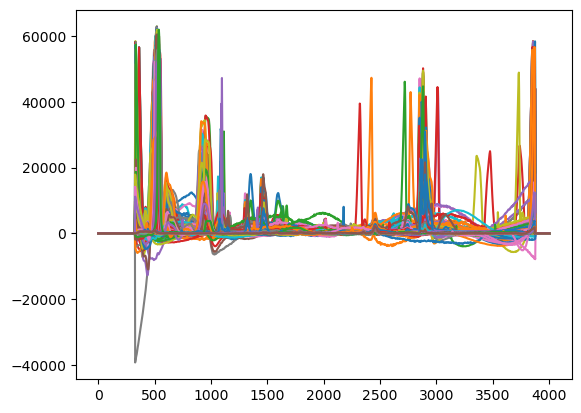

In [121]:
_=plt.plot(spectra_data_raman_int.iloc[:,1:].T)

In [122]:
wl_list = np.float64(spectra_data_int.columns[1:])
wl_list_1 = np.float64(spectra_data.columns[:-7])
#wl_list_2 = np.float64(spectra_data_int.columns[1:])

idx_range = np.logical_or(
    np.logical_and(
        wl_list > wl_list_1.min(),
        wl_list < np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-7])))])).min()-1, #-1
    ),
    np.logical_and(
        wl_list > np.float32((wl_list_1[np.where(np.isnan(np.float32(spectra_data.iloc[0,:-7])))])).max()+1,
        wl_list < wl_list_1.max(),
    )
)
import pickle 
filename = 'gloves_contamination/idx_range.sav'
pickle.dump(idx_range, open(filename, 'wb'))

In [151]:
wl_list_raman = np.float64(spectra_data_raman_int.columns[1:])
wl_list_1_raman = np.float64(spectra_data_raman.columns[:-7])
#wl_list_2_raman = np.float64(spectra_data_raman_int.columns[1:])

idx_range_raman = np.logical_and(
#    np.logical_and(
        wl_list_raman > 600,#wl_list_raman > wl_list_1_raman.min(),
        #wl_list_raman < np.float32((wl_list_1_raman[np.where(np.isnan(np.float32(spectra_data_raman.iloc[0,:-6])))])).min()-1, #-1
    #np.logical_and(
        #wl_list_raman > np.float32((wl_list_1_raman[np.where(np.isnan(np.float32(spectra_data_raman.iloc[0,:-6])))])).max()+1,
        wl_list_raman < 3500#wl_list_raman < wl_list_1_raman.max()
)
import pickle 
filename = 'gloves_contamination/idx_range_raman.sav'
pickle.dump(idx_range_raman, open(filename, 'wb'))

In [124]:
def norm_spect_pivot(x, norm_type='SNV'):
    if norm_type=='SNV':
        return (x - x.mean(1)[:,None]) / x.std(1)[:,None]
    if norm_type=='MINMAX':
        return (x - x.min(1)[:,None]) / (x.max(1)[:,None] - x.min(1)[:,None])
    if norm_type=='Q':
        iqr = np.quantile(x, .8, axis=1)-np.quantile(x, .2, axis=1)
        return (x - np.median(x, 1)[:,None]) / iqr[:,None]

In [136]:
x_train = flopp_flopp_e_pivot.iloc[:,4:].to_numpy()
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='SNV') #MINMAX
x_train = -x_train[:,idx_range]
x_train_diff = np.diff(x_train)

#x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
x_train_diff = norm_spect_pivot(x_train_diff, norm_type='SNV')
y_train = flopp_flopp_e_pivot.iloc[:,2]


In [137]:
spectra_data_np = np.float32(spectra_data_int.iloc[:,1:].to_numpy())
#spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]
spectra_data_np = spectra_data_np[:,idx_range]
spectra_data_np_norm = norm_spect_pivot(spectra_data_np, norm_type='SNV') #MINMAX


spectra_data_diff = np.diff(spectra_data_np_norm)
spectra_data_diff = (spectra_data_diff - spectra_data_diff.mean(1)[:,None]) / spectra_data_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)


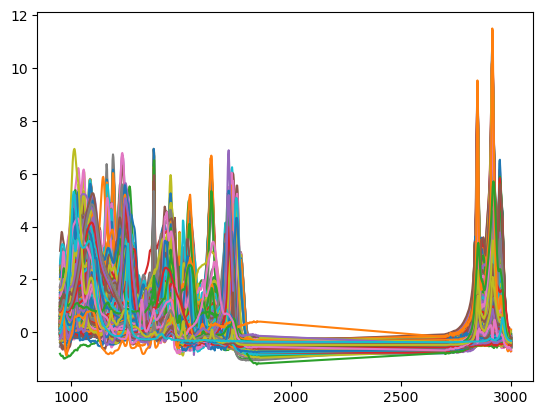

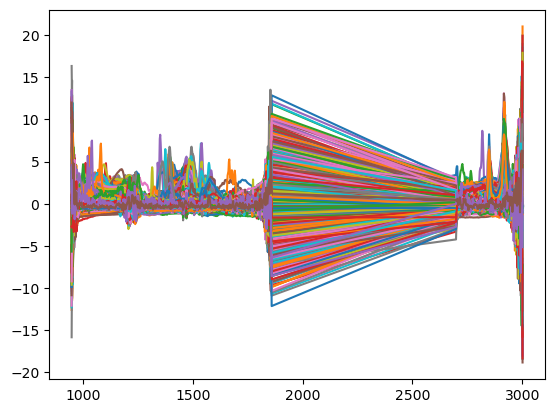

In [138]:
_ = plt.plot(wl_list[idx_range], x_train.T)
_ = plt.show()
_ = plt.plot(wl_list[idx_range], spectra_data_np_norm.T)

In [139]:
pred_ = corr_matching(x_train, y_train, 
                      spectra_data_np_norm, r_min=0)
pred_polymers = pred_[0]
pred_hqi = pred_[1]
pred_df = pd.DataFrame(pred_polymers)
pred_df.columns = ['polymer_flopp']
pred_df['hqi_flopp'] = pred_hqi
pred_df#.reset_index().query('hqi>.7').groupby('polymer').count()

,polymer_flopp,hqi_flopp
74,Polycarbonate,0.713854
123,Polyethylene,0.281597
135,Polyethylene,0.425899
53,Polyethylene Vinyl Acetate,0.054296
371,Rubber,0.142283
...,...,...
141,Polyethylene,0.927433
179,Polyethylene Terephthalate,0.545811
272,Polypropylene,0.147413
10,Acrylonitrile Butadiene Styrene,0.175020


In [152]:
x_train = slopp_slopp_e_pivot.iloc[:,2:].to_numpy()
x_train = x_train[:,idx_range_raman]
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='SNV')

x_train = x_train#[:,:1500]#[:,151:1790]

x_train_diff = np.diff(x_train)
x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = slopp_slopp_e_pivot.iloc[:,1]


In [153]:
spectra_data_raman_np = np.float32(spectra_data_raman_int.iloc[:,1:].to_numpy())
#spectra_data_raman_np_norm = (spectra_data_raman_np[:,idx_range_raman] - spectra_data_raman_np[:,idx_range_raman].mean(1)[:,None]) / spectra_data_raman_np[:,idx_range_raman].std(1)[:,None]
spectra_data_raman_np_norm = norm_spect_pivot(spectra_data_raman_np[:,idx_range_raman], norm_type='SNV') #MINMAX
spectra_data_raman_np_norm = spectra_data_raman_np_norm#[:,:1500]#[:,151:1790]


spectra_data_raman_diff = np.diff(spectra_data_raman_np_norm)
spectra_data_raman_diff = (spectra_data_raman_diff - spectra_data_raman_diff.mean(1)[:,None]) / spectra_data_raman_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)


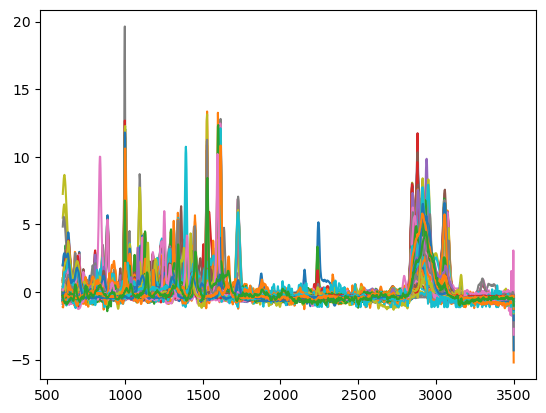

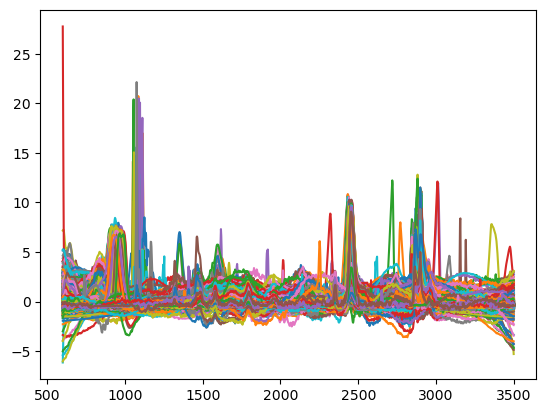

In [154]:
_ = plt.plot(wl_list_raman[idx_range_raman],
             x_train.T)
_ = plt.show()
_ = plt.plot(wl_list_raman[idx_range_raman],
             spectra_data_raman_np_norm.T)

In [155]:
pred_raman = corr_matching(x_train, y_train, 
                           spectra_data_raman_np_norm, r_min=0)
pred_polymers_raman = pred_raman[0]
pred_hqi_raman = pred_raman[1]
pred_df_raman = pd.DataFrame(pred_polymers_raman)
pred_df_raman.columns = ['polymer_slopp']
pred_df_raman['hqi_slopp'] = pred_hqi_raman
pred_df_raman#.query('hqi>.7').reset_index().groupby('polymer').count()

,polymer_slopp,hqi_slopp
117,Polystyrene,0.163774
89,Polymethyl Methacrylate,0.197544
81,Polyethylene Vinyl Acetate,0.171492
81,Polyethylene Vinyl Acetate,0.027046
117,Polystyrene,0.206044
...,...,...
105,Polypropylene,0.281771
117,Polystyrene,0.353421
105,Polypropylene,0.258308
12,Polyamide,0.304707


In [156]:
pd.concat([spectra_data_int.loc[:,'file_name'],#np.concatenate([np.array([True]),idx_range])], 
           pred_df.reset_index(drop=True)], 1)#.to_csv('gloves_contamination/ptir_results.csv')

,file_name,polymer_flopp,hqi_flopp
0,Blank_-_01_0521_1,Polycarbonate,0.713854
1,Blank_-_01_0521_10,Polyethylene,0.281597
2,Blank_-_01_0521_11,Polyethylene,0.425899
3,Blank_-_01_0521_12,Polyethylene Vinyl Acetate,0.054296
4,Blank_-_01_0521_13,Rubber,0.142283
...,...,...,...
1481,MF_N_02_0409_95,Polyethylene,0.927433
1482,MF_N_02_0409_96,Polyethylene Terephthalate,0.545811
1483,MF_N_02_0409_97,Polypropylene,0.147413
1484,MF_N_02_0409_98,Acrylonitrile Butadiene Styrene,0.175020


In [157]:
pd.concat([spectra_data_raman_int.loc[:,'file_name'],#np.concatenate([np.array([True]),idx_range_raman])], 
           pred_df_raman.reset_index(drop=True)], 1)#.to_csv('gloves_contamination/raman_results.csv')

,file_name,polymer_slopp,hqi_slopp
0,Blank_-_01_0521_1,Polystyrene,0.163774
1,Blank_-_01_0521_10,Polymethyl Methacrylate,0.197544
2,Blank_-_01_0521_11,Polyethylene Vinyl Acetate,0.171492
3,Blank_-_01_0521_12,Polyethylene Vinyl Acetate,0.027046
4,Blank_-_01_0521_13,Polystyrene,0.206044
...,...,...,...
1481,MF_N_02_0409_95,Polypropylene,0.281771
1482,MF_N_02_0409_96,Polystyrene,0.353421
1483,MF_N_02_0409_97,Polypropylene,0.258308
1484,MF_N_02_0409_98,Polyamide,0.304707


In [160]:
#(pred_polymers[pred_hqi>.8].to_numpy() == pred_polymers_raman[pred_hqi>.8].to_numpy()).mean()
(pred_polymers[pred_hqi>.7].to_numpy() == pred_polymers_raman[pred_hqi>.7].to_numpy()).mean()

0.4147627416520211

In [37]:
labels = np.unique(np.concatenate([pred_polymers.to_numpy(), pred_polymers_raman.to_numpy()]))

In [38]:
np.unique(pred_polymers.to_numpy())

array(['Acrylic', 'Acrylonitrile Butadiene Styrene', 'Cellulose Acetate',
       'Cotton', 'Ethylene Acrylic Acid', 'Polyamide', 'Polycarbonate',
       'Polyethylene', 'Polyethylene Terephthalate',
       'Polyethylene Vinyl Acetate', 'Polylactic acid',
       'Polymethyl Methacrylate', 'Polypropylene', 'Polystyrene',
       'Polyurethane', 'Polyvinyl Chloride', 'Rubber'], dtype=object)

<AxesSubplot: >

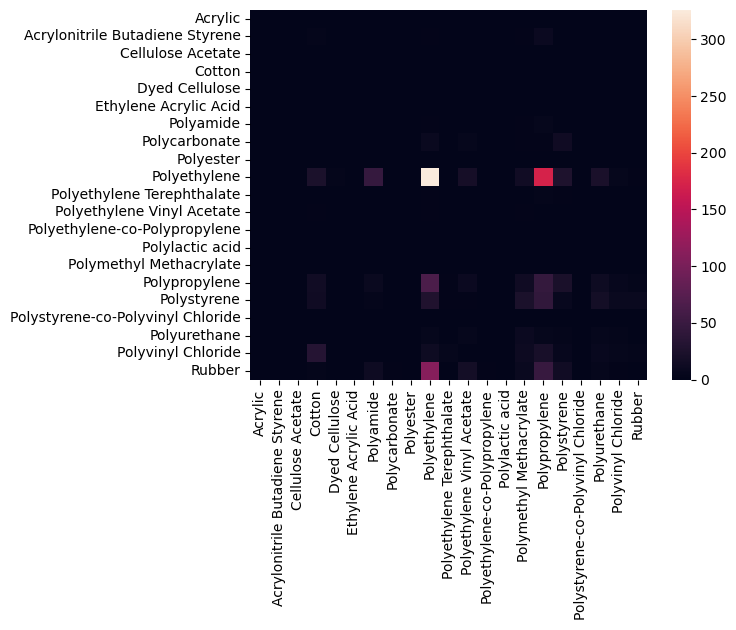

In [161]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

sns.heatmap(confusion_matrix(pred_polymers, pred_polymers_raman, labels=labels), xticklabels=labels, yticklabels=labels)

In [47]:
pd.DataFrame({'ir':pred_polymers[pred_hqi>.5].to_numpy(),
              'raman':pred_polymers_raman[pred_hqi>.5].to_numpy(),
              'n':1}).groupby(['ir','raman']).count().reset_index().query('ir=="Polyethylene"')

,ir,raman,n
9,Polyethylene,Acrylonitrile Butadiene Styrene,1
10,Polyethylene,Cotton,12
11,Polyethylene,Dyed Cellulose,3
12,Polyethylene,Polyamide,24
13,Polyethylene,Polyester,1
14,Polyethylene,Polyethylene,170
15,Polyethylene,Polyethylene Terephthalate,2
16,Polyethylene,Polyethylene-co-Polypropylene,1
17,Polyethylene,Polymethyl Methacrylate,2
18,Polyethylene,Polypropylene,243


In [39]:
#(pred_hqi[np.array(pred_polymers=='Polyethylene').flatten()], 
#            pred_hqi_raman[np.array(pred_polymers=='Polyethylene').flatten()])

In [51]:
np.logical_and(pred_hqi[np.array(pred_polymers=='Polyethylene').flatten()]>.6, 
            pred_hqi_raman[np.array(pred_polymers=='Polyethylene').flatten()]>.6).sum()

281

In [86]:
#clf = LogisticRegression(random_state=0, C=5, penalty='l1', solver='saga')
#clf.fit(x_train, y_train)
#predict = clf.predict(spectra_data_np_norm)
#pd.DataFrame({'polymer':predict, 'n':1}).groupby('polymer').count()

In [52]:
pd.DataFrame([pred_polymers.reset_index(drop=True),
              pd.Series(pred_hqi)]).T.groupby('polymer').mean()

,Unnamed 0
polymer,
Acrylic,0.160648
Acrylonitrile Butadiene Styrene,0.188415
Cellulose Acetate,0.848874
Cotton,0.726848
Ethylene Acrylic Acid,0.207574
Polyamide,0.150267
Polycarbonate,0.497897
Polyethylene,0.674451
Polyethylene Terephthalate,0.100502


In [53]:
pd.DataFrame([pred_polymers_raman.reset_index(drop=True),
              pd.Series(pred_hqi_raman)]).T.groupby('polymer').mean()

,Unnamed 0
polymer,
Acrylic,0.039249
Acrylonitrile Butadiene Styrene,0.317652
Cotton,0.282723
Dyed Cellulose,0.314408
Polyamide,0.660378
Polyester,0.414786
Polyethylene,0.371628
Polyethylene Terephthalate,0.062369
Polyethylene Vinyl Acetate,0.266180


Acrylic 1


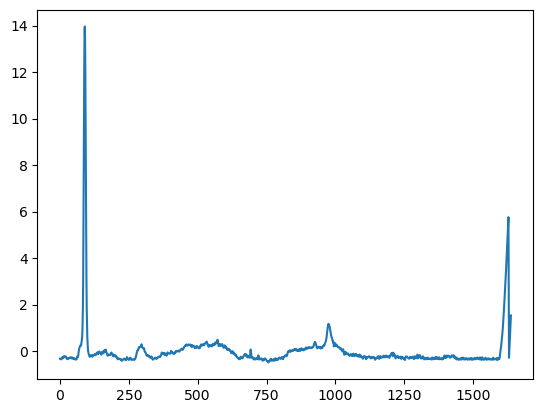

Acrylonitrile Butadiene Styrene 2


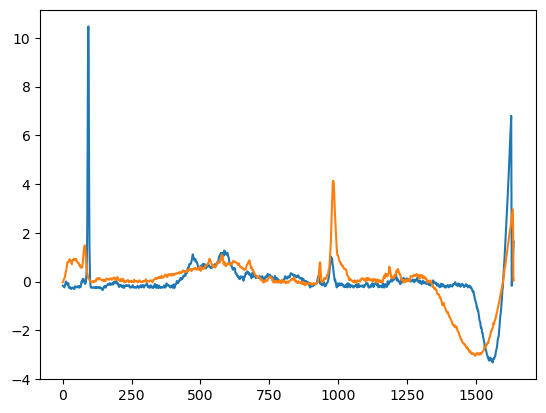

Cotton 47


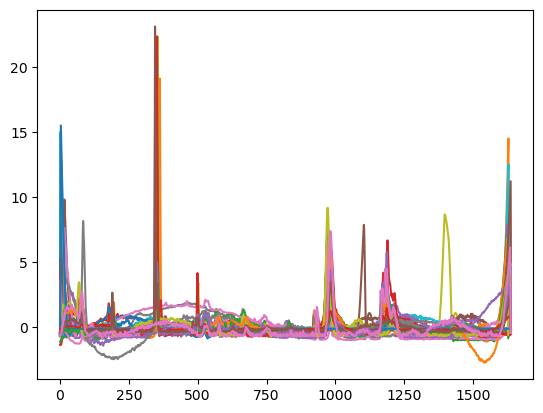

Dyed Cellulose 6


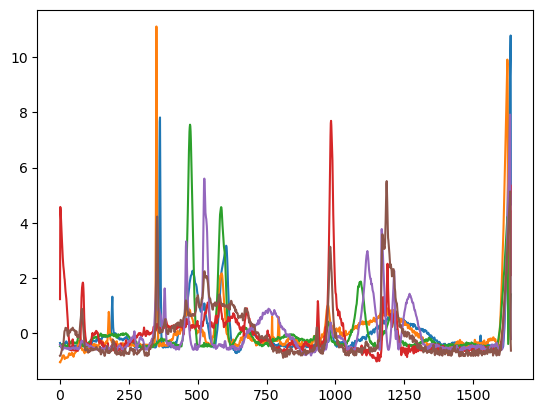

Polyamide 39


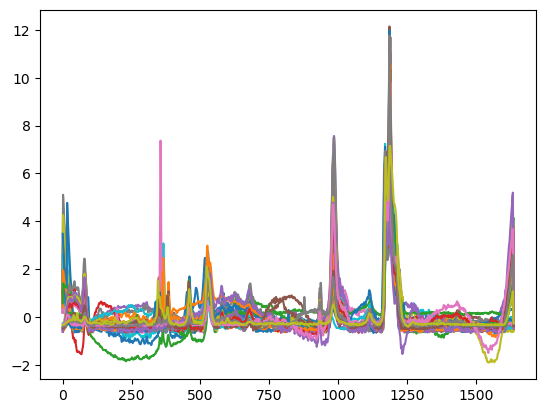

Polyester 1


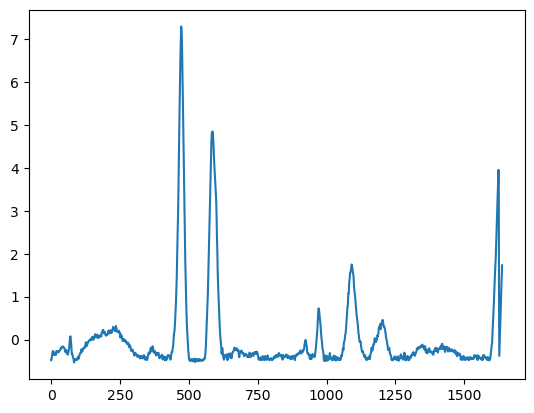

Polyethylene 317


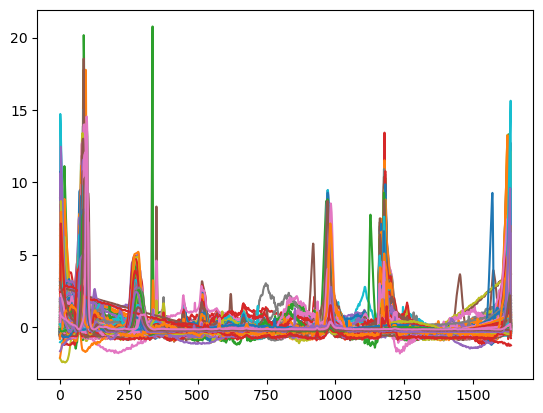

Polyethylene Terephthalate 3


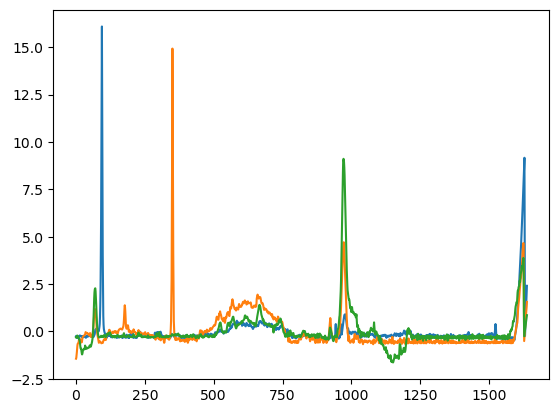

Polyethylene-co-Polypropylene 2


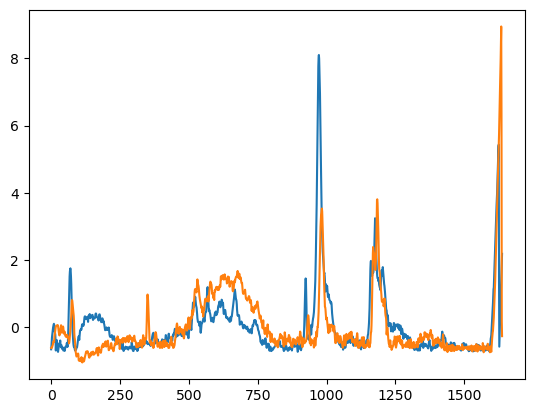

Polymethyl Methacrylate 6


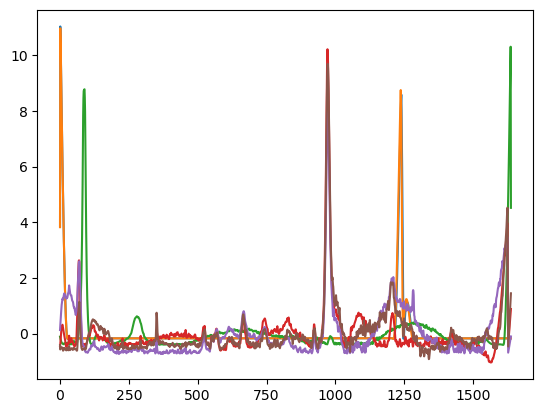

Polypropylene 339


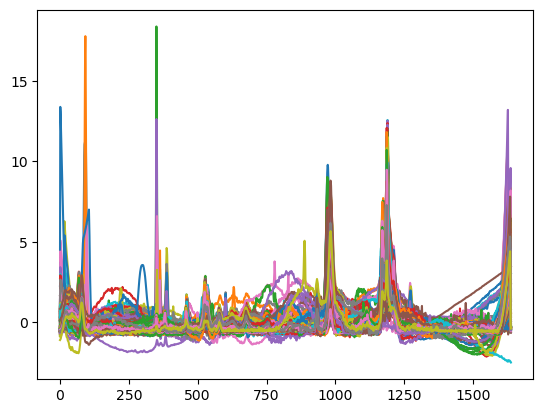

Polystyrene 36


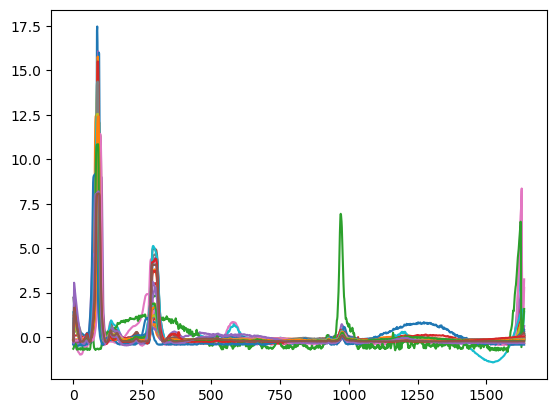

Polystyrene-co-Polyvinyl Chloride 1


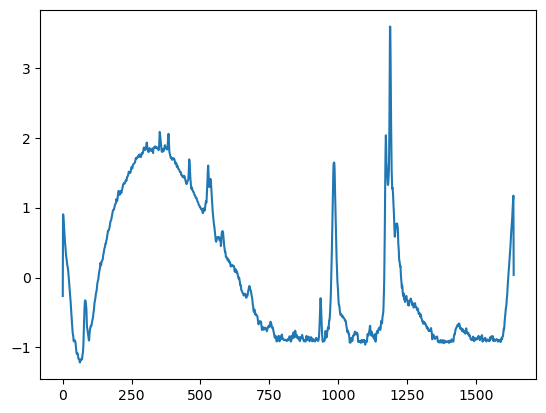

Polyurethane 15


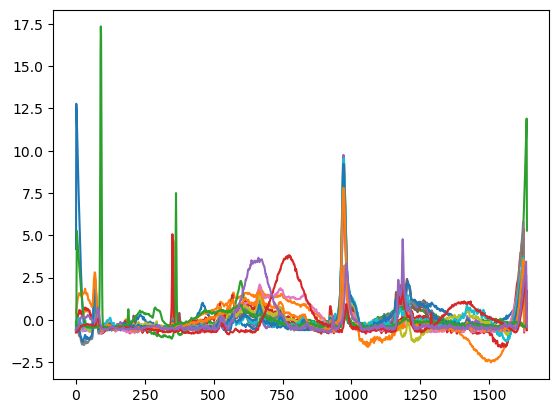

Polyvinyl Chloride 8


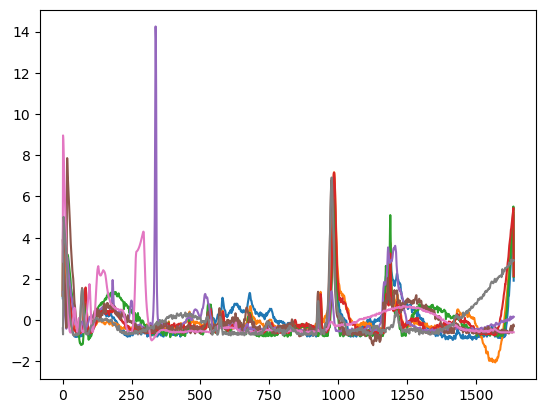

Rubber 12


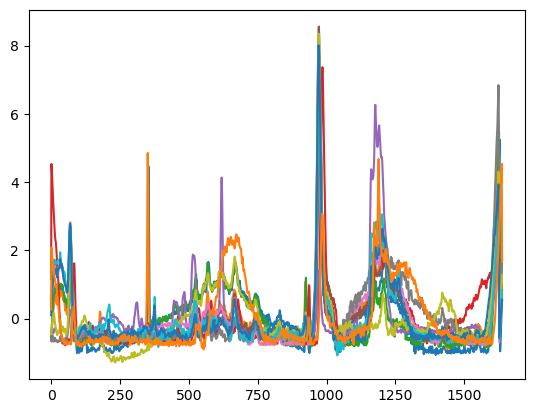

In [54]:
match_idx = pred_hqi>.4

for p in np.unique(pred_polymers_raman):
    
    idx = np.logical_and(match_idx, np.array(pred_polymers_raman)==p)
    if sum(idx) == 0:
        continue
    print(p, sum(idx))
    
    
    plt.plot(spectra_data_raman_np_norm[idx,:].T)
    plt.show()

In [55]:
mgstearate_data_ir = pd.read_csv('gloves_contamination/mgstearate_ir_20240409.csv')
del mgstearate_data_ir['Unnamed: 0']
mgstearate_data_ir['id'] = np.arange(mgstearate_data_ir.shape[0])

mgstearate_data_raman = pd.read_csv('gloves_contamination/mgstearate_raman_20240409.csv')
del mgstearate_data_raman['Unnamed: 0']
mgstearate_data_raman['id'] = np.arange(mgstearate_data_raman.shape[0])

In [56]:
mgstearate_data_ir_long = mgstearate_data_ir.melt(id_vars='id')#
mgstearate_data_ir_long.iloc[:,1:] = mgstearate_data_ir_long.iloc[:,1:].astype('float32')

mgstearate_data_ir_long.columns = ['file_name','wavelength','intensity']
mgstearate_data_ir_long['polymer'] = ''
mgstearate_data_ir_long_int = interpol_spect(mgstearate_data_ir_long, min_wl=674.9918, max_wl=3999.809,n=1725)
mgstearate_data_ir_int = mgstearate_data_ir_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()


mgstearate_data_raman_long = mgstearate_data_raman.melt(id_vars='id')#
mgstearate_data_raman_long.iloc[:,1:] = mgstearate_data_raman_long.iloc[:,1:].astype('float32')

mgstearate_data_raman_long.columns = ['file_name','wavelength','intensity']
mgstearate_data_raman_long['polymer'] = ''
mgstearate_data_raman_long_int = interpol_spect(mgstearate_data_raman_long, min_wl=0, max_wl=3999.57,n=1846)                                               
mgstearate_data_raman_int = mgstearate_data_raman_long_int.pivot(
    index=['file_name'], 
    columns='wavelength', 
    values='intensity').reset_index()

mgstearate_data_ir_np = np.float32(mgstearate_data_ir_int.iloc[:,1:].to_numpy())
#spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]
mgstearate_data_ir_np = mgstearate_data_ir_np[:,idx_range]
mgstearate_data_ir_np_norm = norm_spect_pivot(mgstearate_data_ir_np, norm_type='SNV') #MINMAX


mgstearate_data_raman_np = np.float32(mgstearate_data_raman_int.iloc[:,1:].to_numpy())
#spectra_data_np_norm = (spectra_data_np[:,idx_range] - spectra_data_np[:,idx_range].mean(1)[:,None]) / spectra_data_np[:,idx_range].std(1)[:,None]
mgstearate_data_raman_np = mgstearate_data_raman_np[:,idx_range_raman]
mgstearate_data_raman_np_norm = norm_spect_pivot(mgstearate_data_raman_np, norm_type='SNV') #MINMAX


In [57]:
mgstearate_data_ir_np_norm

array([[-0.41364387, -0.432287  , -0.37440923, ..., -0.2476257 ,
        -0.1857741 , -0.26470175],
       [-0.5037723 , -0.49966574, -0.5226407 , ..., -0.33783987,
        -0.3462762 , -0.31801105],
       [-0.52903676, -0.52274233, -0.5224934 , ..., -0.32869342,
        -0.33943355, -0.35151926],
       ...,
       [-0.37572992, -0.3404711 , -0.32746094, ...,  0.70201325,
         0.5914858 ,  0.49006653],
       [-0.70256895, -0.6802825 , -0.6398556 , ..., -0.6025332 ,
        -0.6811144 , -0.75627965],
       [-0.64726067, -0.65014017, -0.6440937 , ..., -0.4789735 ,
        -0.52776766, -0.57053745]], dtype=float32)

In [58]:
n_ref = mgstearate_data_ir_np_norm.shape[0]
R = np.corrcoef(mgstearate_data_ir_np_norm, spectra_data_np_norm)[:n_ref, n_ref:]

(np.nanmax(R, axis=0)>.70).sum()

527

In [59]:
pred_df_mgstearate_ir = pd.DataFrame(np.nanmax(R, axis=0))
pred_df_mgstearate_ir.columns = ['hqi_mgstearate_ir']
pred_df_mgstearate_ir

,hqi_mgstearate_ir
0,0.179859
1,0.189215
2,0.497597
3,0.141508
4,0.263978
...,...
1481,0.852649
1482,-0.059537
1483,0.117653
1484,0.059268


In [60]:
#pd.DataFrame(np.nanmax(R, axis=0)).to_csv('top_hqi_mgstearate_ir.csv')

In [61]:
n_ref = mgstearate_data_raman_np_norm.shape[0]
R = np.corrcoef(mgstearate_data_raman_np_norm, spectra_data_raman_np_norm)[:n_ref, n_ref:]

(np.nanmax(R, axis=0)>.70).sum()

395

In [62]:
pred_df_mgstearate_raman = pd.DataFrame(np.nanmax(R, axis=0))
pred_df_mgstearate_raman.columns = ['hqi_mgstearate_raman']
pred_df_mgstearate_raman

,hqi_mgstearate_raman
0,0.248083
1,0.364867
2,0.301182
3,0.214522
4,0.314359
...,...
1481,0.457464
1482,0.302984
1483,0.339867
1484,0.308216


In [63]:
#pd.DataFrame(np.nanmax(R, axis=0)).to_csv('top_hqi_mgstearate_raman.csv')

In [64]:
corr_matching(mgstearate_data_raman_np_norm, 
              pd.Series(['mgstearate']*49), 
              spectra_data_raman_np_norm, r_min=0)

(13    mgstearate
 13    mgstearate
 13    mgstearate
 13    mgstearate
 13    mgstearate
          ...    
 13    mgstearate
 13    mgstearate
 13    mgstearate
 13    mgstearate
 13    mgstearate
 Length: 1486, dtype: object,
 array([nan, nan, nan, ..., nan, nan, nan]))

In [65]:
labRam_1 = pd.read_csv('/Users/eochoa/Documents/rebbeca_library_labRam_1.csv')
labRam_2 = pd.read_csv('/Users/eochoa/Documents/rebbeca_library_labRam_2.csv')
mIRange_ir = pd.read_csv('/Users/eochoa/Documents/rebbeca_library_mIRange_ir.csv')
mIRange_raman = pd.read_csv('/Users/eochoa/Documents/rebbeca_library_mIRange_raman.csv')

In [162]:
labRam_1_long = labRam_1.melt(id_vars=['file_name', 'polymer'])#
labRam_1_long.iloc[:,2:] = labRam_1_long.iloc[:,2:].astype('float32')
labRam_1_long.columns = ['file_name','polymer','wavelength','intensity']
labRam_1_long_int = interpol_spect(labRam_1_long, min_wl=0, max_wl=3999.57,n=1846)

labRam_1_int = labRam_1_long_int.pivot(
    index=['file_name','polymer'], 
    columns='wavelength', 
    values='intensity').reset_index()

labRam_2_long = labRam_2.melt(id_vars=['file_name', 'polymer'])#
labRam_2_long.iloc[:,2:] = labRam_2_long.iloc[:,2:].astype('float32')
labRam_2_long.columns = ['file_name','polymer','wavelength','intensity']
labRam_2_long_int = interpol_spect(labRam_2_long, min_wl=0, max_wl=3999.57,n=1846)

labRam_2_int = labRam_2_long_int.pivot(
    index=['file_name','polymer'], 
    columns='wavelength', 
    values='intensity').reset_index()

mIRange_raman_long = mIRange_raman.melt(id_vars=['file_name', 'polymer'])#
mIRange_raman_long.iloc[:,2:] = mIRange_raman_long.iloc[:,2:].astype('float32')
mIRange_raman_long.columns = ['file_name','polymer','wavelength','intensity']
mIRange_raman_long_int = interpol_spect(mIRange_raman_long, min_wl=0, max_wl=3999.57,n=1846)

mIRange_raman_int = mIRange_raman_long_int.pivot(
    index=['file_name','polymer'], 
    columns='wavelength', 
    values='intensity').reset_index()

rebbeca_library_raman = pd.concat([labRam_1_int,labRam_2_int,mIRange_raman_int],axis=0).reset_index(drop=True)


mIRange_ir_long = mIRange_ir.melt(id_vars=['file_name', 'polymer'])#
mIRange_ir_long.iloc[:,2:] = mIRange_ir_long.iloc[:,2:].astype('float32')
mIRange_ir_long.columns = ['file_name','polymer','wavelength','intensity']
mIRange_ir_long_int = interpol_spect(mIRange_ir_long, min_wl=674.9918, max_wl=3999.809,n=1725)

mIRange_ir_int = mIRange_ir_long_int.pivot(
    index=['file_name','polymer'], 
    columns='wavelength', 
    values='intensity').reset_index()

mIRange_ir_int

wavelength,file_name,polymer,674.9918,676.9203482598608,678.8488965197216,680.7774447795824,682.7059930394431,684.6345412993039,686.5630895591647,688.4916378190255,...,3982.452065661253,3984.3806139211138,3986.3091621809745,3988.237710440835,3990.1662587006967,3992.0948069605574,3994.023355220418,3995.951903480279,3997.8804517401395,3999.809
0,mIRange1,LDPE,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,mIRange2,AFR,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,mIRange3,AFR,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,mIRange4,PSL,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,mIRange5,PP,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [163]:
x_train = mIRange_ir_int.iloc[:,2:].to_numpy()
x_train = x_train[:,idx_range]
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='SNV')

x_train = x_train#[:,:1500]#[:,151:1790]

x_train_diff = np.diff(x_train)
x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = mIRange_ir_int.iloc[:,1]


In [164]:
pred_rebb_ir = corr_matching(x_train, y_train, 
                      spectra_data_np_norm, r_min=0)
pred_polymers_rebb_ir = pred_rebb_ir[0]
pred_hqi_rebb_ir = pred_rebb_ir[1]
pred_df_rebb_ir = pd.DataFrame(pred_polymers_rebb_ir)
pred_df_rebb_ir.columns = ['polymer_std_reb_ir']
pred_df_rebb_ir['hqi_std_reb_ir'] = pred_hqi_rebb_ir
pred_df_rebb_ir#.reset_index().query('hqi>.7').groupby('polymer').count()

,polymer_std_reb_ir,hqi_std_reb_ir
3,PSL,-0.087129
2,AFR,0.256242
0,LDPE,0.352219
0,LDPE,0.033346
3,PSL,0.287839
...,...,...
0,LDPE,0.942157
2,AFR,0.050152
2,AFR,0.112484
2,AFR,0.049024


In [234]:
x_train = rebbeca_library_raman.iloc[:,2:].to_numpy()
x_train = x_train[:,idx_range_raman]
#x_train = (x_train - x_train.mean(1)[:,None]) / x_train.std(1)[:,None]
x_train = norm_spect_pivot(x_train, norm_type='SNV')

x_train = x_train#[:,:1500]#[:,151:1790]

x_train_diff = np.diff(x_train)
x_train_diff = (x_train_diff - x_train_diff.mean(1)[:,None]) / x_train_diff.std(1)[:,None] #/ (spectra_data_diff.shape[1]**0.5)
y_train = rebbeca_library_raman.iloc[:,1]


ValueError: x and y must have same first dimension, but have shapes (1846,) and (1338,)

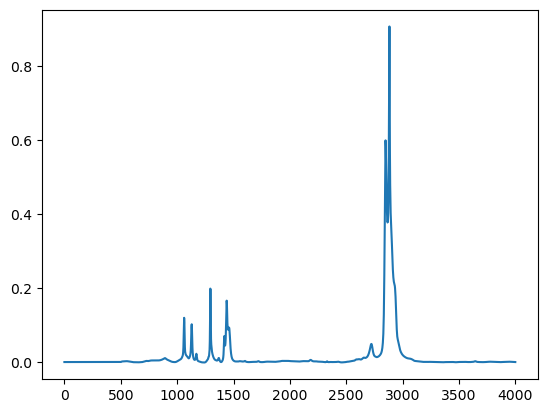

In [238]:
for i in range(8):
    plt.plot(rebbeca_library_raman.iloc[i,2:])
    plt.plot(rebbeca_library_raman.iloc[i:(i+1),2:].columns,
             x_train[i,:])
    plt.show()

In [211]:
corr_shfted = np.array([np.abs(x_train[:,i:] @ spectra_data_raman_np_norm[:,:-i].T)/x_train[:,i:].shape[1] for i in range(1,30)] + 
                       [np.abs(x_train[:,:-i] @ spectra_data_raman_np_norm[:,i:].T)/x_train[:,:-i].shape[1] for i in range(1,30)])

(np.argmax(np.abs(x_train @ spectra_data_raman_np_norm.T) / x_train.shape[1],0),
 np.argmax(corr_shfted.max(0),0))

(array([6, 6, 4, ..., 7, 7, 7]), array([6, 7, 6, ..., 5, 5, 5]))

In [226]:
corr_shfted.max(0)[:,2]

array([0.07081973, 0.40409397, 0.03894653, 0.18963059, 0.19892717,
       0.07060701, 0.41818532, 0.04931077])

In [212]:
corr_shfted = np.array([np.abs(x_train[:,i:] @ spectra_data_raman_np_norm[:,:-i].T)/x_train[:,i:].shape[1] for i in range(1,30)] + 
                       [np.abs(x_train[:,:-i] @ spectra_data_raman_np_norm[:,i:].T)/x_train[:,:-i].shape[1] for i in range(1,30)])

(np.max(np.abs(x_train @ spectra_data_raman_np_norm.T) / x_train.shape[1],0),
 np.max(corr_shfted.max(0),0))

(array([0.15644605, 0.17341791, 0.19916257, ..., 0.25731151, 0.31718099,
        0.30520638]),
 array([0.39399134, 0.20533775, 0.41818532, ..., 0.32863632, 0.35910041,
        0.42438026]))

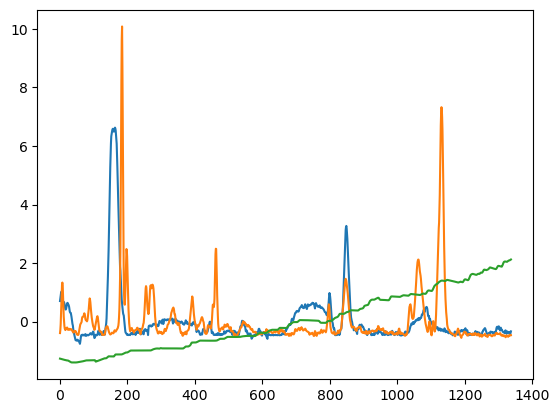

In [228]:
plt.plot(spectra_data_raman_np_norm[2])
plt.plot(x_train[6])
plt.plot(x_train[4])
#plt.plot(x_train[6][28:])

In [70]:
pred_rebb_raman = corr_matching(x_train, y_train, 
                           spectra_data_raman_np_norm, r_min=0)
pred_polymers_rebb_raman = pred_rebb_raman[0]
pred_hqi_rebb_raman = pred_rebb_raman[1]
pred_df_rebb_raman = pd.DataFrame(pred_polymers_rebb_raman)
pred_df_rebb_raman.columns = ['polymer_std_reb_raman']
pred_df_rebb_raman['hqi_std_reb_raman'] = pred_hqi_rebb_raman
pred_df_rebb_raman#.query('hqi>.7').reset_index().groupby('polymer').count()

,polymer_std_reb_raman,hqi_std_reb_raman
7,PP,-0.006583
6,PSL,0.096669
5,LDPE,-0.017530
6,PSL,-0.002858
6,PSL,0.034307
...,...,...
7,PP,0.251305
6,PSL,0.011304
7,PP,0.148485
3,AFR,0.096177


In [1]:
particles_data = pd.read_csv('gloves_contamination/particle_info_rest.csv')
del particles_data['Unnamed: 0']
particles_data

NameError: name 'pd' is not defined

In [214]:
spectra_data_int.to_csv('gloves_contamination/spectra_data_ir.csv')
spectra_data_raman_int.to_csv('gloves_contamination/spectra_data_raman.csv')

In [87]:
pred_all = pd.concat([spectra_data_int.loc[:,'file_name'],
           pred_df.reset_index(drop=True),
           pred_df_raman.reset_index(drop=True),
           pred_df_mgstearate_ir.reset_index(drop=True),
           pred_df_mgstearate_raman.reset_index(drop=True),
           pred_df_rebb_ir.reset_index(drop=True),
           pred_df_rebb_raman.reset_index(drop=True)
           ], 1)
pred_all

,file_name,polymer_flopp,hqi_flopp,polymer_slopp,hqi_slopp,hqi_mgstearate_ir,hqi_mgstearate_raman,polymer_std_reb_ir,hqi_std_reb_ir,polymer_std_reb_raman,hqi_std_reb_raman
0,Blank_-_01_0521_1,Polycarbonate,0.713854,Polystyrene,0.086860,0.179859,0.248083,PSL,-0.087129,PP,-0.006583
1,Blank_-_01_0521_10,Polyethylene,0.281597,Polyethylene,0.119943,0.189215,0.364867,AFR,0.256242,PSL,0.096669
2,Blank_-_01_0521_11,Polyethylene,0.425899,Polyethylene,0.096113,0.497597,0.301182,LDPE,0.352219,LDPE,-0.017530
3,Blank_-_01_0521_12,Polyethylene Vinyl Acetate,0.054296,Polystyrene,0.078811,0.141508,0.214522,LDPE,0.033346,PSL,-0.002858
4,Blank_-_01_0521_13,Rubber,0.142283,Polystyrene,0.123406,0.263978,0.314359,PSL,0.287839,PSL,0.034307
...,...,...,...,...,...,...,...,...,...,...,...
1481,MF_N_02_0409_95,Polyethylene,0.927433,Polypropylene,0.258484,0.852649,0.457464,LDPE,0.942157,PP,0.251305
1482,MF_N_02_0409_96,Polyethylene Terephthalate,0.545811,Polyethylene,0.100910,-0.059537,0.302984,AFR,0.050152,PSL,0.011304
1483,MF_N_02_0409_97,Polypropylene,0.147413,Polyurethane,0.139820,0.117653,0.339867,AFR,0.112484,PP,0.148485
1484,MF_N_02_0409_98,Acrylonitrile Butadiene Styrene,0.175020,Polyethylene,0.112449,0.059268,0.308216,AFR,0.049024,AFR,0.096177


(array([259., 222., 169., 139.,  99., 101., 103., 127., 162., 105.]),
 array([-0.07847193,  0.02717983,  0.13283159,  0.23848335,  0.34413511,
         0.44978687,  0.55543863,  0.66109039,  0.76674215,  0.8723939 ,
         0.97804566]),
 <BarContainer object of 10 artists>)

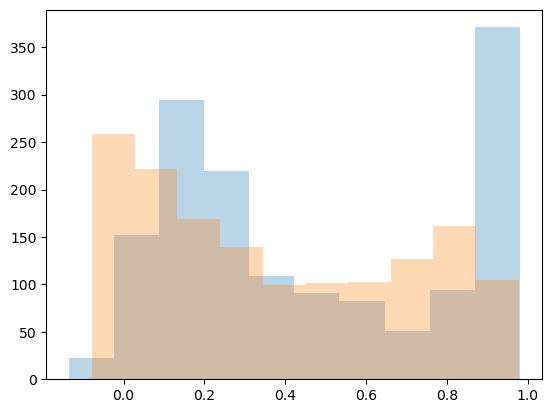

In [95]:
plt.hist(pred_all['hqi_std_reb_ir'], alpha=.3)
plt.hist(pred_all['hqi_std_reb_raman'], alpha=.3)

(array([ 34., 127., 216., 218., 194., 161., 142., 152., 117., 125.]),
 array([0.05542232, 0.14780169, 0.24018106, 0.33256044, 0.42493981,
        0.51731918, 0.60969856, 0.70207793, 0.7944573 , 0.88683667,
        0.97921605]),
 <BarContainer object of 10 artists>)

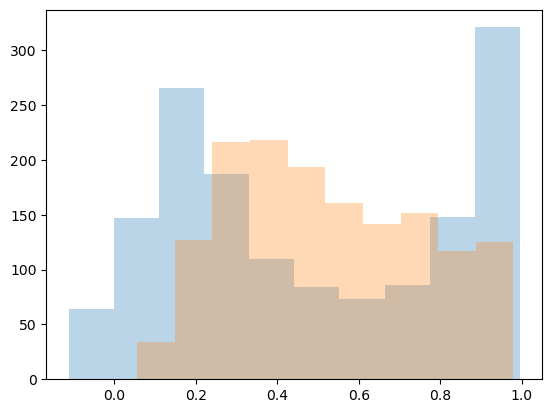

In [94]:
plt.hist(pred_all['hqi_mgstearate_ir'], alpha=.3)
plt.hist(pred_all['hqi_mgstearate_raman'], alpha=.3)

(array([ 27., 224., 272., 203., 126., 118., 118., 125., 158., 115.]),
 array([-0.10515472,  0.00352913,  0.11221299,  0.22089684,  0.32958069,
         0.43826455,  0.5469484 ,  0.65563225,  0.76431611,  0.87299996,
         0.98168381]),
 <BarContainer object of 10 artists>)

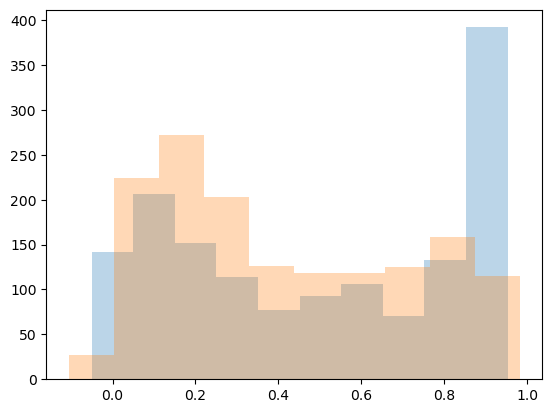

In [93]:
plt.hist(pred_all['hqi_flopp'], alpha=.3)
plt.hist(pred_all['hqi_slopp'], alpha=.3)

In [73]:
print(pred_all.groupby('polymer_flopp').count()['file_name'])

polymer_flopp
Acrylic                              4
Acrylonitrile Butadiene Styrene     22
Cellulose Acetate                    1
Cotton                               5
Ethylene Acrylic Acid                1
Polyamide                            9
Polycarbonate                       30
Polyethylene                       664
Polyethylene Terephthalate           9
Polyethylene Vinyl Acetate          10
Polylactic acid                      1
Polymethyl Methacrylate              3
Polypropylene                      204
Polystyrene                        158
Polyurethane                        35
Polyvinyl Chloride                 105
Rubber                             225
Name: file_name, dtype: int64


In [74]:
print(pred_all.groupby('polymer_slopp').count()['file_name'])

polymer_slopp
Acrylic                                1
Acrylonitrile Butadiene Styrene        7
Cotton                               108
Dyed Cellulose                        10
Polyamide                             54
Polyester                              1
Polyethylene                         513
Polyethylene Terephthalate             9
Polyethylene Vinyl Acetate             2
Polyethylene-co-Polypropylene          7
Polymethyl Methacrylate               45
Polypropylene                        500
Polystyrene                           88
Polystyrene-co-Polyvinyl Chloride      3
Polyurethane                          53
Polyvinyl Chloride                    55
Rubber                                30
Name: file_name, dtype: int64


In [75]:
print(pred_all.groupby('polymer_std_reb_ir').count()['file_name'])

polymer_std_reb_ir
AFR     362
LDPE    705
PP      121
PSL     298
Name: file_name, dtype: int64


In [77]:
print(pred_all.groupby('polymer_std_reb_raman').count()['file_name'])

polymer_std_reb_raman
AFR     195
LDPE    253
PP      775
PSL     263
Name: file_name, dtype: int64


In [79]:
particles_data#.merge(pred_all, left_on='id_x', right_on='file_name')

,id_x,map_x_x,map_y_x,brand,run,day,map_x_y,map_y_y,size,area,perimeter,circularity,id_y,distance
0,MF_01_0514_1,15624.450195,1545.449951,MF,1,514,15624.230,1545.722,1.374926,1.330287,5.386343,0.575968,MF_1/_1_33_1,0.349995
1,MF_01_0514_2,15623.299805,1550.750000,MF,1,514,15623.290,1550.499,0.651304,0.302916,2.497942,0.609815,MF_1/_1_33_2,0.251191
2,MF_01_0514_3,15617.500000,1564.949951,MF,1,514,15617.680,1564.703,1.388501,1.506106,5.563866,0.611143,MF_1/_1_33_3,0.305589
3,MF_01_0514_4,15620.650391,1565.050049,MF,1,514,15620.600,1565.341,1.632973,1.673451,6.535387,0.492165,MF_1/_1_33_4,0.295283
4,MF_01_0514_5,15616.150391,1570.400024,MF,1,514,15616.280,1570.091,0.636946,0.275378,2.199516,0.715016,MF_1/_1_33_5,0.335104
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1373,KC_02_0328_28,-4543.500000,-1759.750000,KC,2,328,-4543.314,-1760.015,1.422096,1.533643,4.995885,0.771863,KC_2/_1_475_7,0.323761
1374,KC_02_0328_29,-4501.899902,-1758.099976,KC,2,328,-4501.917,-1758.334,1.331205,1.357825,4.697458,0.772963,KC_2/_1_475_8,0.234648
1375,KC_02_0328_30,-4510.850098,-1747.099976,KC,2,328,-4510.644,-1747.328,0.694288,0.379174,2.628095,0.689600,KC_2/_1_475_9,0.307362
1376,KC_02_0328_31,-4511.100098,-1743.050049,KC,2,328,-4511.191,-1743.359,2.594529,5.022470,9.855076,0.649588,KC_2/_1_475_10,0.322047


In [258]:
particles_data.merge(pred_all, left_on='id_x', right_on='file_name').to_csv('gloves_contamination/result_matches_part_size.csv')


(array([343., 138.,  27.,   7.,   4.,   1.,   0.,   0.,   0.,   1.]),
 array([ 0.2300343 ,  1.62648687,  3.02293944,  4.41939201,  5.81584458,
         7.21229715,  8.60874972, 10.00520229, 11.40165486, 12.79810743,
        14.19456   ]),
 <BarContainer object of 10 artists>)

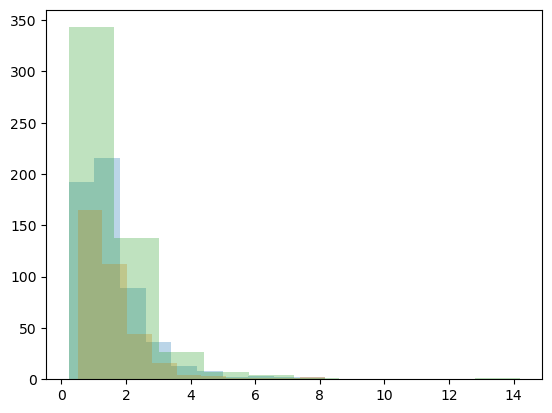

In [88]:
plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_flopp>.7')['size'], alpha=.3)
plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_slopp>.7')['size'], alpha=.3)
plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_mgstearate_ir>.7')['size'], alpha=.3)
#plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_mgstearate_raman>.7')['size'], alpha=.3)



(array([162., 112.,  44.,  16.,   4.,   3.,   1.,   1.,   1.,   2.]),
 array([0.5024738 , 1.26811602, 2.03375824, 2.79940046, 3.56504268,
        4.3306849 , 5.09632712, 5.86196934, 6.62761156, 7.39325378,
        8.158896  ]),
 <BarContainer object of 10 artists>)

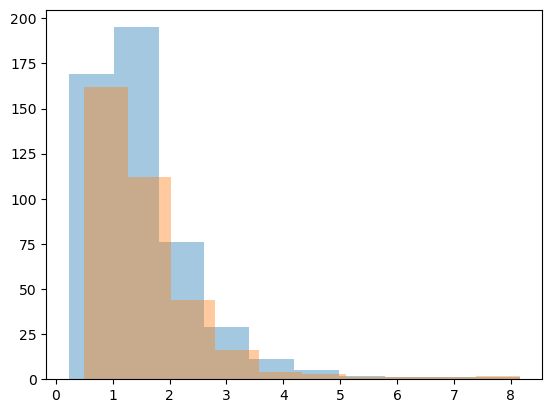

In [89]:
plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_std_reb_ir>.7')['size'], alpha=.4)
plt.hist(particles_data.merge(pred_all, left_on='id_x', right_on='file_name').query('hqi_std_reb_raman>.7')['size'], alpha=.4)


In [83]:
nans_ = np.unique(np.where(np.isnan(spectra_data_raman_np_norm))[0])

In [102]:
np.unique(np.where(np.isnan(spectra_data_np_norm))[0])

array([1276])

In [128]:
file_names_nans = spectra_data_raman_int.iloc[np.unique(np.where(np.isnan(spectra_data_raman_np_norm))[0]),0].to_numpy()

In [139]:
#plt.plot(spectra_data_raman.iloc[np.unique(np.where(np.isnan(spectra_data_raman_np_norm))[0]),1:].T)


array([  87,  420,  450,  476, 1275])

In [88]:
spectra_data_raman_np_norm[~np.array([i in nans_ for i in range(1491)]),:]

array([[ 0.09022193,  0.08604732,  0.08898081, ..., -0.196786  ,
        -0.19504286, -0.20028555],
       [-0.0751428 , -0.02821659,  0.04152299, ..., -0.79832757,
        -0.8175767 , -0.83817047],
       [ 0.5776851 ,  0.56482536,  0.5619854 , ..., -0.24694256,
        -0.24322487, -0.23881805],
       ...,
       [ 0.9568706 ,  0.93118083,  0.909909  , ...,  0.41401306,
         0.4285025 ,  0.42961064],
       [ 0.7131837 ,  0.7245736 ,  0.72276664, ..., -0.29446986,
        -0.29824284, -0.29879323],
       [ 1.1142915 ,  1.0879694 ,  1.0644481 , ..., -0.3716563 ,
        -0.3720402 , -0.3739698 ]], dtype=float32)

In [325]:
from sklearn.cluster import KMeans

#X_IR = (X_IR - X_IR.mean(0)) / X_IR.std(0)
kmeans = KMeans(n_clusters=16, random_state=0).fit(spectra_data_np_norm)
print(kmeans.labels_)
#y_hat_ir_clus = kmeans.predict(spectra_data_raman_np_norm[~np.array([i in nans_ for i in range(1491)]),:])
y_hat_ir_clus = kmeans.predict(spectra_data_np_norm)
pd.DataFrame({'label':y_hat_ir_clus,'n':1}).groupby('label').count()


[13  0  5 ...  9  0  1]


,n
label,
0,125
1,196
2,61
3,64
4,121
5,86
6,21
7,68
8,72


In [326]:
pred_all.loc[y_hat_ir_clus == 1, 'polymer_flopp']

258      Polyethylene
313      Polyethylene
350      Polyethylene
351      Polyethylene
355      Polyethylene
            ...      
1344    Polypropylene
1359     Polyethylene
1366     Polyethylene
1381     Polyethylene
1485    Polypropylene
Name: polymer_flopp, Length: 196, dtype: object

In [327]:
label_table = pd.DataFrame({'polymer':labels,'label':np.arange(labels.shape[0])})
np.array(label_table.set_index('polymer').loc[np.array(pred_polymers_raman),'label'])

array([13, 12,  7, ...,  7,  7,  7])

In [328]:
np.array(pred_polymers_raman)

array(['Polystyrene', 'Polypropylene', 'Polyethylene', ...,
       'Polyethylene', 'Polyethylene', 'Polyethylene'], dtype=object)

In [329]:
label_table#[np.array(pred_polymers_raman)]


,polymer,label
0,Acrylic,0
1,Acrylonitrile Butadiene Styrene,1
2,Cellulose Acetate,2
3,Cotton,3
4,Ethylene Acrylic Acid,4
5,Polyamide,5
6,Polycarbonate,6
7,Polyethylene,7
8,Polyethylene Terephthalate,8
9,Polyethylene Vinyl Acetate,9


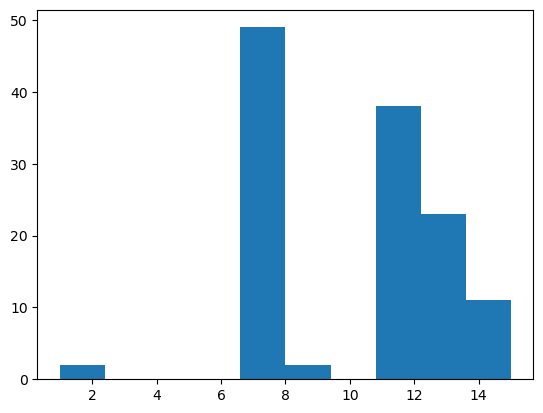

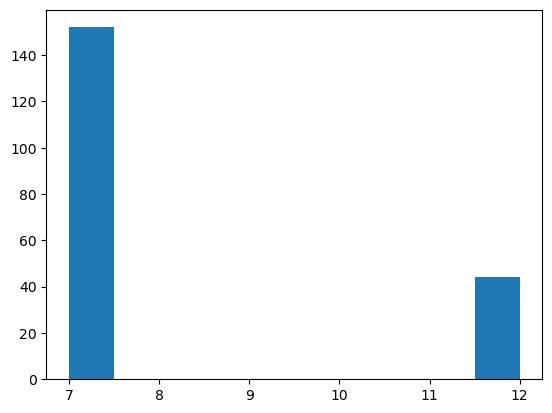

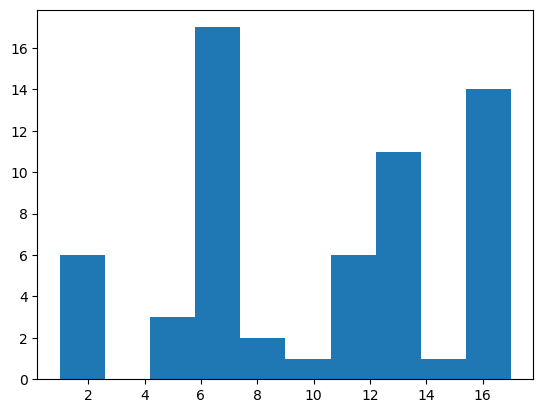

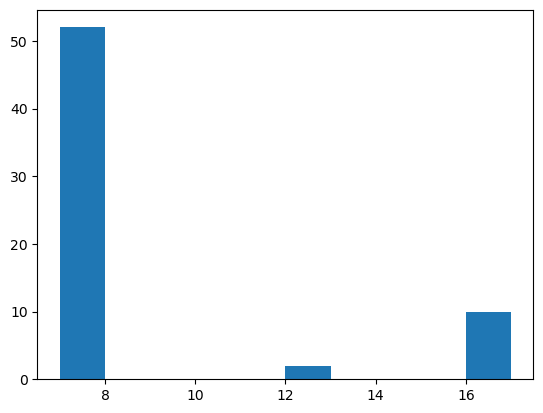

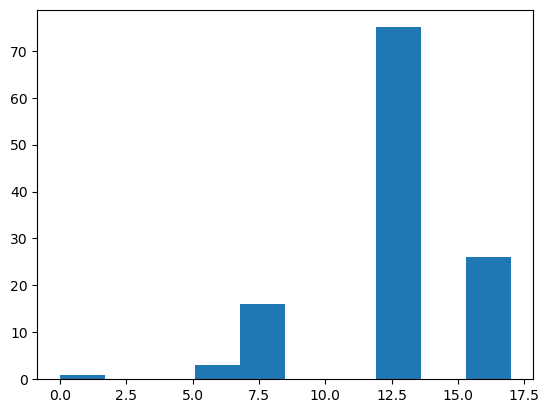

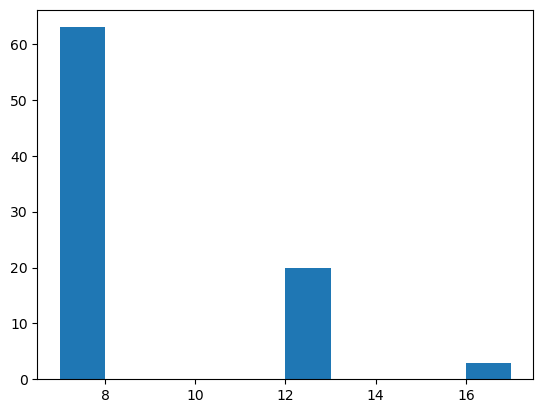

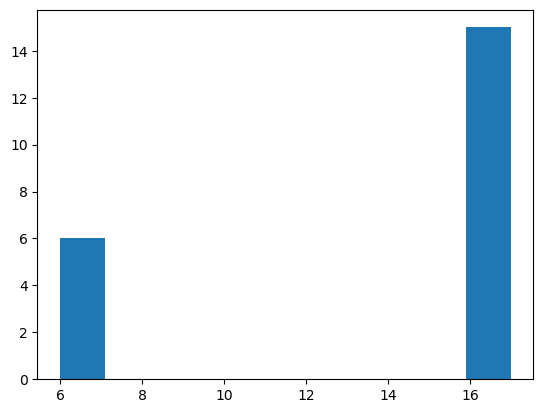

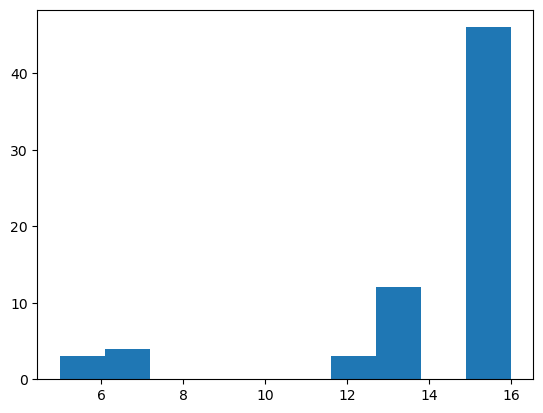

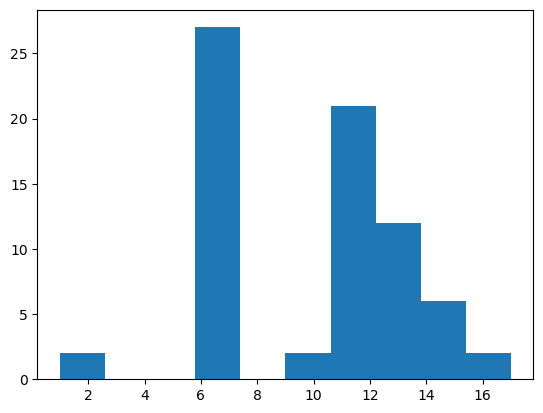

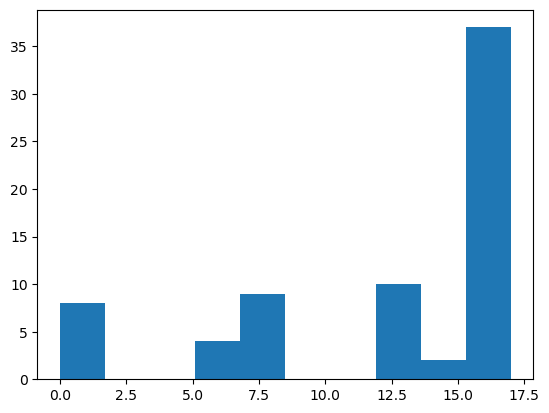

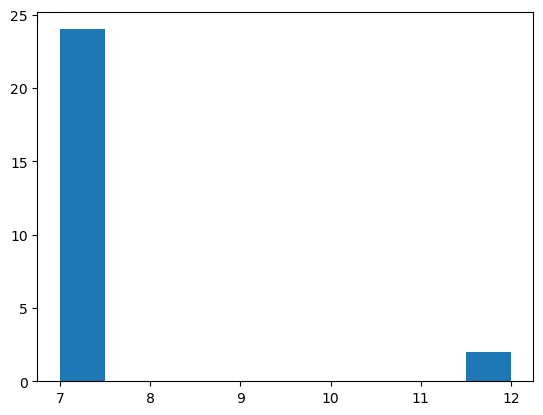

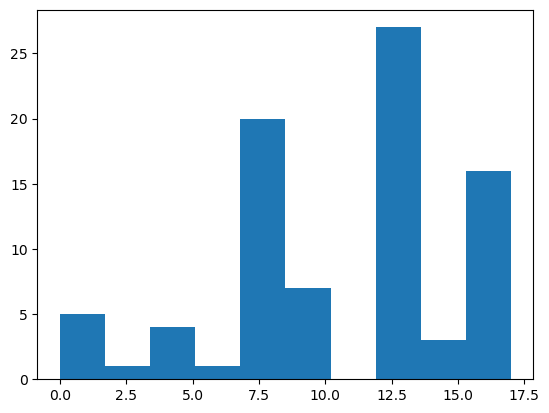

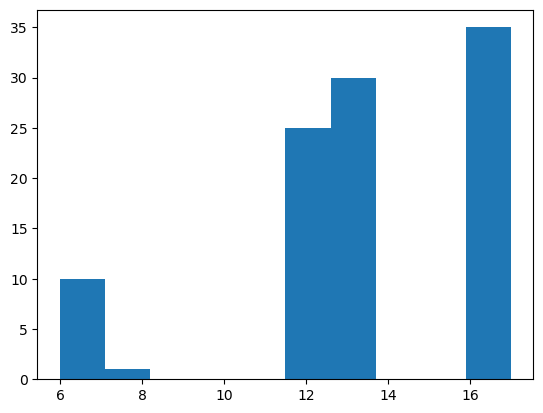

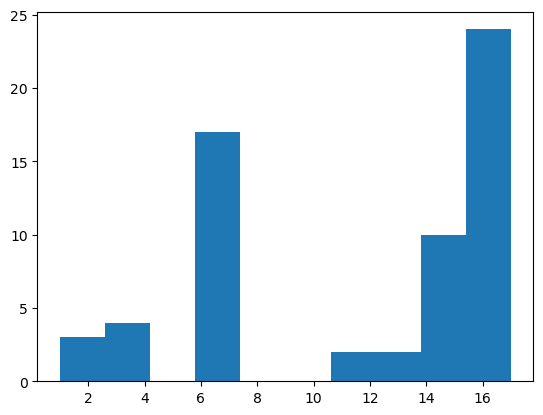

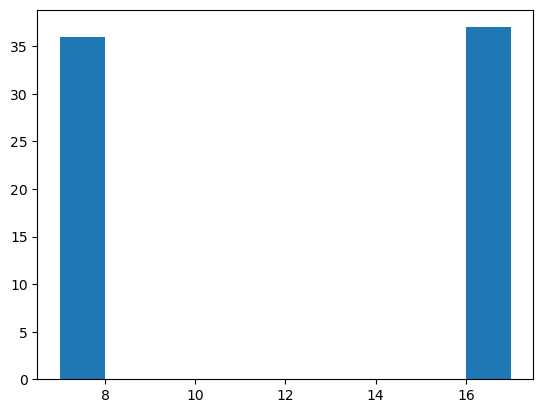

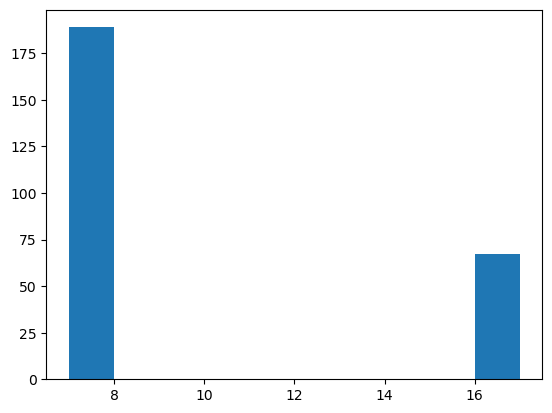

In [335]:
for i in range(16):
    plt.hist(np.array(label_table.set_index('polymer').loc[np.array(pred_polymers)[y_hat_ir_clus==i],'label']))
    plt.show()

<AxesSubplot: >

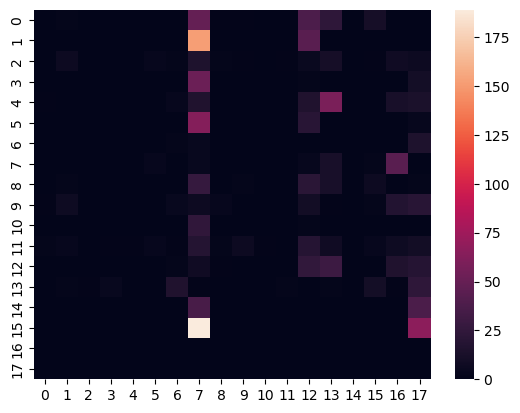

In [331]:
sns.heatmap(confusion_matrix(y_hat_ir_clus, 
                             np.array(label_table.set_index('polymer').loc[np.array(pred_polymers),'label'])))#, labels=labels,)


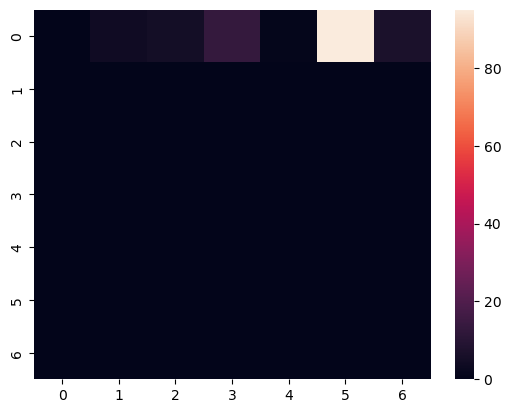

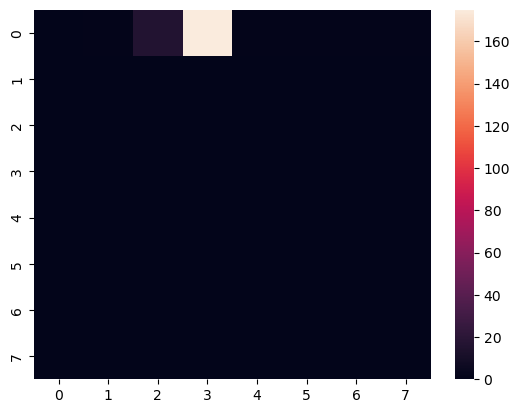

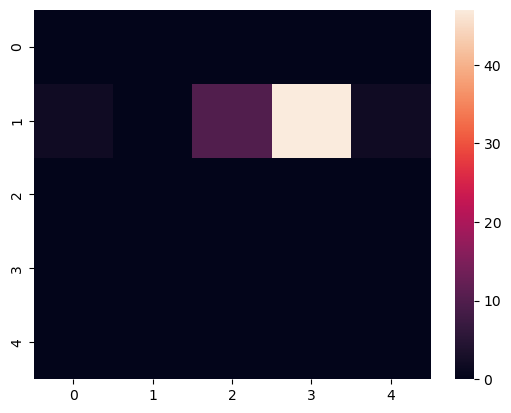

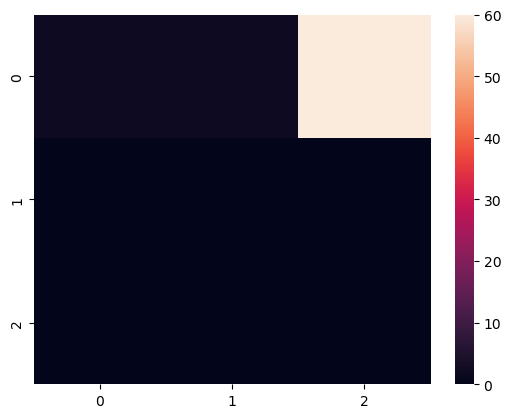

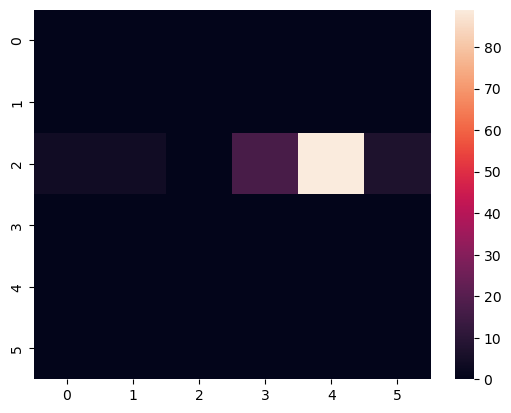

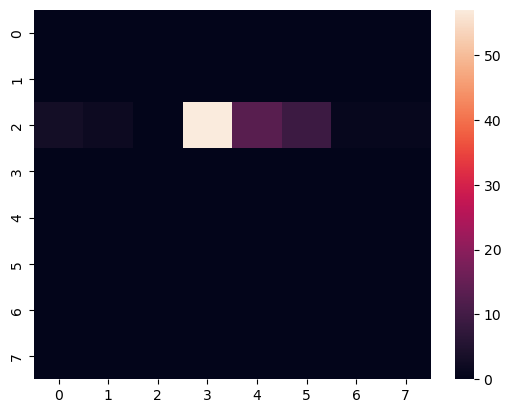

In [332]:
for i in range(6):
    sns.heatmap(confusion_matrix(y_hat_ir_clus[y_hat_ir_clus==i], 
                    np.array(label_table.set_index('polymer').loc[np.array(pred_polymers_raman)[y_hat_ir_clus==i],'label'])))#, labels=labels,)
    plt.show()


<AxesSubplot: >

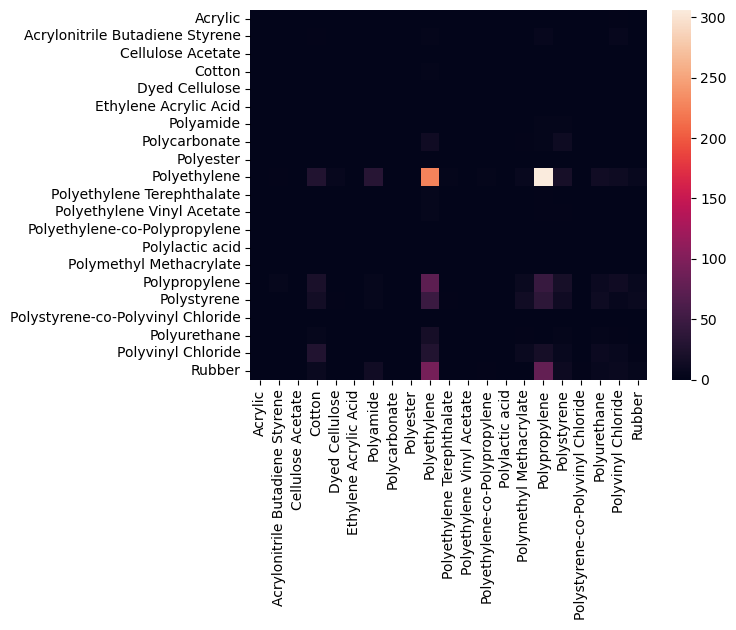

In [84]:
sns.heatmap(confusion_matrix(pred_polymers, pred_polymers_raman, labels=labels), xticklabels=labels, yticklabels=labels)



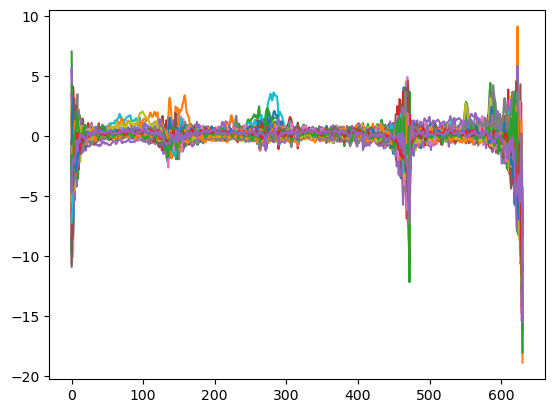

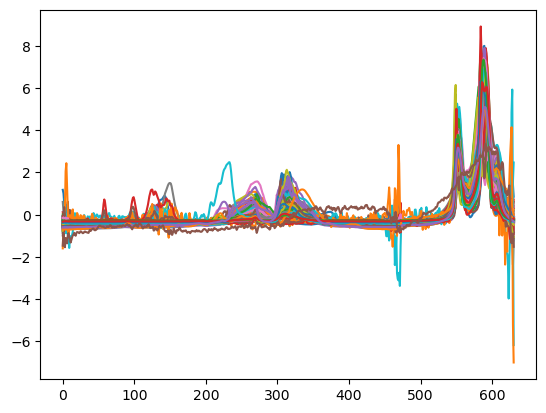

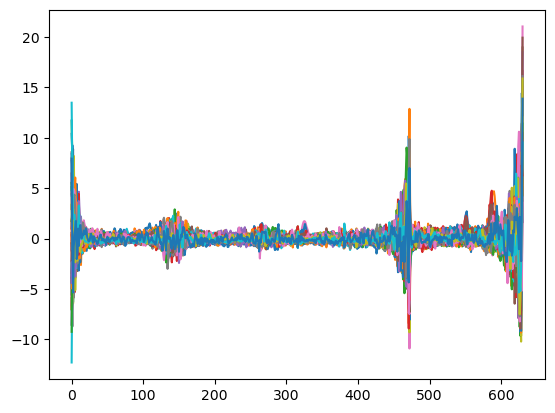

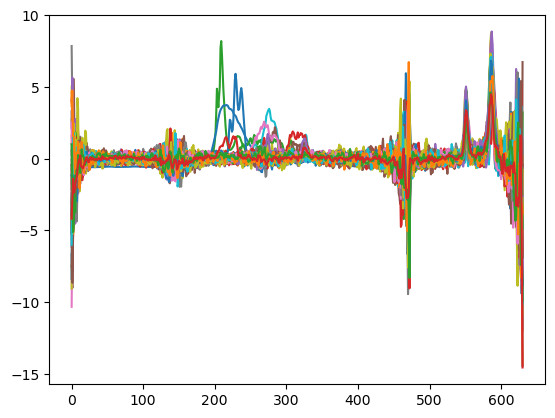

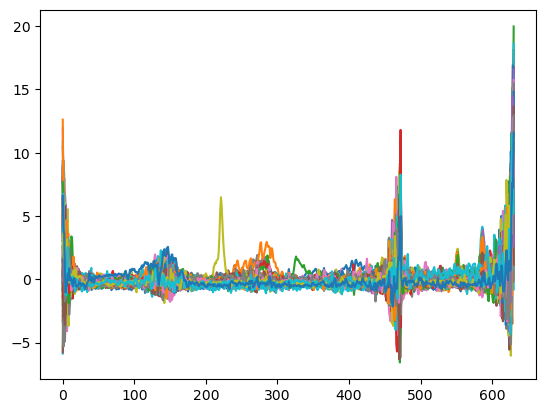

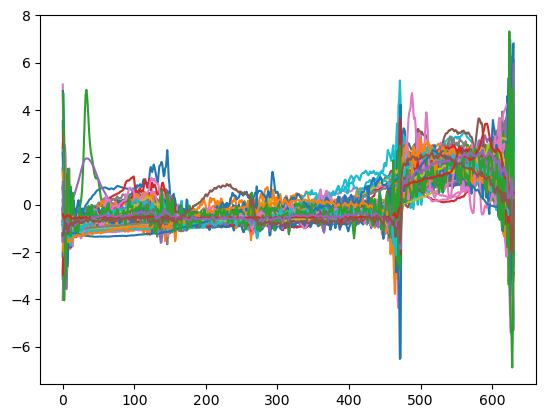

In [334]:
for j in range(6):
    _=plt.plot(spectra_data_np_norm[y_hat_ir_clus == j].T)
    plt.show()